In [1]:
# Debe fijarse ANTES de que se inicialice CUDA, para permitir operaciones
# deterministas en cuBLAS (matmul) en GPU.
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import os, re
import time
import pandas as pd
import subprocess
import sys
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import torch.nn.functional as F
import copy
import numpy as np
from torchvision.transforms import InterpolationMode
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              ConfusionMatrixDisplay)

In [2]:
import random

# --- Dispositivo de cómputo: usa GPU si está disponible, si no CPU ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo utilizado:", DEVICE)

# --- Semilla base para reproducibilidad entre experimentos ---
BASE_SEED = 42

def set_seed(seed: int = BASE_SEED):
    """Fija la semilla en random, numpy y torch (CPU y GPU) para que los
    distintos experimentos (baseline, L2, dropout, etc.) partan de las
    mismas condiciones de inicialización y así sean comparables."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # --- Determinismo en GPU ---
    # Por defecto, cuDNN puede elegir algoritmos de convolución no deterministas
    # (auto-tuning). Esto es lo que hacía que, con la misma seed, corridas en GPU
    # dieran resultados distintos entre sesiones. Forzamos modo determinista:
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)


    torch.use_deterministic_algorithms(True, warn_only=True)

def plot_history(history, title=""):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure()
    plt.plot(epochs, history["train_loss"], label="Train Loss")
    plt.plot(epochs, history["val_loss"], label="Val Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.xticks(range(1, len(epochs) + 1))
    plt.title(title)
    plt.legend()
    plt.show()

    plt.figure()
    plt.plot(epochs, history["train_acc"], label="Train Accuracy")
    plt.plot(epochs, history["val_acc"], label="Val Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.xticks(range(1, len(epochs) + 1))
    plt.title(title)
    plt.legend()
    plt.show()


Dispositivo utilizado: cuda


# 1.Leer la base de datos

In [3]:
# Detectamos si estamos en Google Colab (para decidir dónde guardar/clonar).
IN_COLAB = 'google.colab' in sys.modules
print("Ejecutando en Colab:", IN_COLAB)

# Carpeta donde vamos a clonar el repositorio de datos.
DATA_DIR = "/content/glaucomaPGUSab" if IN_COLAB else "./glaucomaPGUSab"

# Clonamos el repo solo si no existe ya (para no descargarlo dos veces).
if not os.path.isdir(DATA_DIR):
    print("Clonando repositorio de datos...")
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/valentinaache/glaucomaPGUSab", DATA_DIR],
        check=True
    )
else:
    print("El repositorio ya existe en", DATA_DIR)

# Rutas a las carpetas/archivos que vamos a necesitar.
IMAGES_DIR  = os.path.join(DATA_DIR, "FundusImages")            # carpeta con las 488 imágenes .jpg
CLINICAL_OD = os.path.join(DATA_DIR, "ClinicalData", "patient_data_od.xlsx")  # datos clínicos "OD"
CLINICAL_OS = os.path.join(DATA_DIR, "ClinicalData", "patient_data_os.xlsx")  # datos clínicos "OS"

print("Número de imágenes encontradas:", len(os.listdir(IMAGES_DIR)))

Ejecutando en Colab: True
El repositorio ya existe en /content/glaucomaPGUSab
Número de imágenes encontradas: 488


In [4]:
# Ruta al único archivo clínico que necesitamos (ver explicación más abajo
# de por qué patient_data_od.xlsx no se usa).
CLINICAL_OS = os.path.join(DATA_DIR, "ClinicalData", "patient_data_os.xlsx")

# --- Paso 1: dataframe de imágenes a partir de los nombres de archivo ---
imagenes_info = []
for filename in sorted(os.listdir(IMAGES_DIR)):  # sorted: orden estable entre sesiones/sistemas de archivos
    if filename.endswith(".jpg"):
        base = filename.replace(".jpg", "")   # "RET002OD"
        id_paciente = base[3:-2]              # "002"
        tipo_ojo = base[-2:]                  # "OD" u "OS"
        imagenes_info.append({
            "filename": os.path.join(IMAGES_DIR, filename),
            "id": id_paciente,
            "eye": tipo_ojo
        })
imagenes_df = pd.DataFrame(imagenes_info)
print("Imágenes indexadas:", len(imagenes_df))

# --- Paso 2: leer el archivo clínico ---
# patient_data_os.xlsx, a pesar de su nombre, contiene el diagnóstico de AMBOS
# ojos de los 244 pacientes (488 filas = 244 pacientes x 2 ojos). Por eso no
# necesitamos combinarlo con patient_data_od.xlsx (que es un subconjunto parcial,
# solo OD, de esta misma información — usarlo también generaría duplicados).
data_os = pd.read_excel(CLINICAL_OS)
print("\nEjemplo 'Unnamed: 0' en data_os:", data_os["Unnamed: 0"].head().tolist())

# --- Paso 3: función para limpiar el id y extraer el ojo real desde el texto ---
def limpiar_id_y_ojo(valor):
    if not isinstance(valor, str):
        return None, None
    m = re.match(r"#(\d+)\s*(od|os)?", valor.strip(), re.IGNORECASE)
    if not m:
        return None, None
    id_limpio = m.group(1)
    ojo = m.group(2).upper() if m.group(2) else None
    return id_limpio, ojo

# --- Paso 4: aplicar la limpieza ---
ids_os = data_os["Unnamed: 0"].apply(limpiar_id_y_ojo)
data_os["id"] = ids_os.apply(lambda x: x[0])
data_os["eye"] = ids_os.apply(lambda x: x[1])
data_os = data_os[data_os["id"].notna()]     # bota filas basura (nan, 'ID', etc.)

print("Filas válidas en data_os:", len(data_os))

# --- Paso 5: tabla clínica final ---
data_clinica = data_os[["id", "eye", "Diagnosis"]].copy()
print("Duplicados en data_clinica (id, eye):",
      data_clinica.duplicated(subset=["id", "eye"]).sum())

# --- Paso 6: unir (merge) los datos clínicos con las imágenes ---
full_df = pd.merge(imagenes_df, data_clinica, on=["id", "eye"], how="left")

# --- Paso 7: excluir la clase 'glaucoma suspect' (Diagnosis == 2) ---
full_df = full_df[full_df["Diagnosis"] != 2].copy()
full_df["label"] = full_df["Diagnosis"].astype(int)   # 0 = sano, 1 = glaucoma

# --- Paso 8: verificación final ---
print("\n=== Verificación ===")
print("Total de imágenes originales:", len(imagenes_df))
print("Diagnosis = NaN (merge fallido):",
      pd.merge(imagenes_df, data_clinica, on=["id", "eye"], how="left")["Diagnosis"].isna().sum())
print("Filas duplicadas por 'filename':", full_df.duplicated(subset=["filename"]).sum())
print("\nFilas finales tras excluir clase 'sospechoso' (2):", len(full_df))

Imágenes indexadas: 488

Ejemplo 'Unnamed: 0' en data_os: [nan, 'ID', '#002 od', '#002 os', '#004 od']
Filas válidas en data_os: 488
Duplicados en data_clinica (id, eye): 0

=== Verificación ===
Total de imágenes originales: 488
Diagnosis = NaN (merge fallido): 0
Filas duplicadas por 'filename': 0

Filas finales tras excluir clase 'sospechoso' (2): 420


- Exploración

=== Conteo de imágenes por clase ===
label
Healthy     333
Glaucoma     87
Name: count, dtype: int64

=== Conteo de imágenes por ojo (OD / OS) ===
eye
OD    210
OS    210
Name: count, dtype: int64

=== Número de pacientes distintos ===
210

=== Dimensiones originales (muestra de 10 imágenes) ===
  RET140OS.jpg (2576, 1934)
  RET245OD.jpg (2576, 1934)
  RET157OS.jpg (2576, 1934)
  RET265OS.jpg (2576, 1934)
  RET292OD.jpg (2576, 1934)
  RET062OS.jpg (2576, 1934)
  RET134OD.jpg (2576, 1934)
  RET136OS.jpg (2576, 1934)
  RET029OD.jpg (2576, 1934)
  RET062OD.jpg (2576, 1934)

Tamaños únicos encontrados en la muestra: {(2576, 1934)}


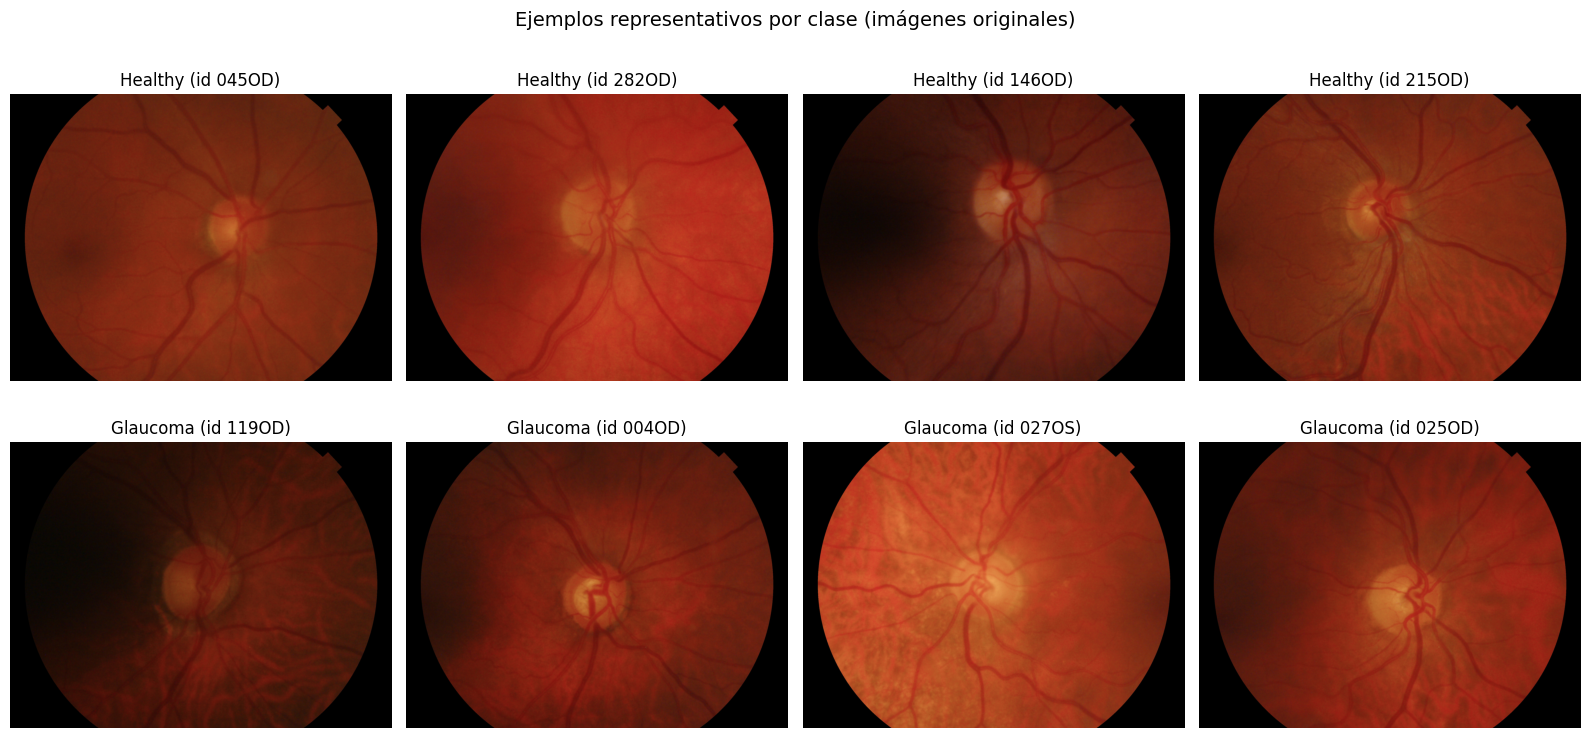

In [5]:
# --- 1) Conteos por clase (ya los vimos en la lectura, los repetimos aquí
#        como parte formal de la exploración que pide el enunciado) ---
print("=== Conteo de imágenes por clase ===")
print(full_df["label"].map({0: "Healthy", 1: "Glaucoma"}).value_counts())
print()
print("=== Conteo de imágenes por ojo (OD / OS) ===")
print(full_df["eye"].value_counts())
print()
print("=== Número de pacientes distintos ===")
print(full_df["id"].nunique())


# --- 2) Dimensiones originales de las imágenes ---
# Tomamos una muestra (no todas, para no abrir 420 imágenes sin necesidad)
# y verificamos si todas comparten la misma resolución original.
sample_files = full_df["filename"].sample(10, random_state=42)
sizes = [Image.open(fp).size for fp in sample_files]  # (ancho, alto)

print("\n=== Dimensiones originales (muestra de 10 imágenes) ===")
for fp, sz in zip(sample_files, sizes):
    print(" ", os.path.basename(fp), sz)

unique_sizes = set(sizes)
print("\nTamaños únicos encontrados en la muestra:", unique_sizes)


# --- 3) Ejemplos visuales representativos de cada clase ---
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row, label in enumerate([0, 1]):
    ejemplos = full_df[full_df["label"] == label].sample(4, random_state=42)
    for col, (_, r) in enumerate(ejemplos.iterrows()):
        img = Image.open(r["filename"])
        axes[row, col].imshow(img)
        axes[row, col].set_title(
            f"{'Healthy' if label == 0 else 'Glaucoma'} (id {r['id']}{r['eye']})"
        )
        axes[row, col].axis("off")

plt.suptitle("Ejemplos representativos por clase (imágenes originales)", fontsize=14)
plt.tight_layout()
plt.show()

El dataset PAPILA utilizado contiene 420 imágenes de fondo de ojo tras excluir la clase sospechoso de glaucoma, distribuidas en 333 casos sanos (79%) y 87 casos de glaucoma (21%), lo que evidencia un desbalance de clases moderado a tener en cuenta más adelante. Las imágenes provienen de 210 pacientes, cada uno con ambos ojos (OD y OS) representados, y todas comparten la misma resolución original de 2576×1934 píxeles. La inspección visual confirma que el disco óptico es claramente visible en todas las muestras y que existen diferencias morfológicas observables entre clases (mayor excavación del disco en los casos de glaucoma), lo cual es consistente con el criterio clínico usado para el diagnóstico.

In [6]:
PARTITION_PATH = "./partition.csv"

# Si ya existe una partición guardada de una corrida anterior, la reutilizamos
# tal cual (garantiza 100% la misma asignación train/val/test entre sesiones,
# sin depender de que el pipeline de arriba sea perfectamente reproducible).
if os.path.exists(PARTITION_PATH):
    print(f"Cargando partición ya existente desde {PARTITION_PATH} "
          "(no se regenera para garantizar reproducibilidad).")
    df_partitioned = pd.read_csv(PARTITION_PATH)
else:
    # --- Paso 1: diagnóstico dominante por paciente ---
    dominant_diagnosis     = full_df.groupby("id")["label"].agg(lambda x: x.mode()[0])
    patient_df = pd.DataFrame(dominant_diagnosis).reset_index()

    # --- Paso 2: split train/test a nivel de paciente (80/20, seed=42), igual que en el repositorio de referencia ---
    splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_idx, test_idx = next(splitter.split(patient_df, patient_df["label"]))

    train_ids_full = patient_df.iloc[train_idx]["id"]   # 80% de los pacientes
    test_ids = patient_df.iloc[test_idx]["id"]           # 20% de los pacientes -> ESTE es el test final

    train_patient_df = patient_df[patient_df["id"].isin(train_ids_full)].reset_index(drop=True)

    # --- Paso 3: del 80% de train se separa validación (el repositorio de referencia
    #     solo hace train/test). Se usa la misma técnica y la misma semilla.
    #     test_size=0.1875 sobre el 80% equivale a 15% del total:
    #     0.8 * 0.1875 = 0.15  ->  proporciones finales: 65% train / 15% val / 20% test
    val_splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.1875, random_state=42)
    tr_idx, val_idx = next(val_splitter.split(train_patient_df, train_patient_df["label"]))

    train_ids = train_patient_df.iloc[tr_idx]["id"]
    val_ids = train_patient_df.iloc[val_idx]["id"]

    # --- Paso 4: mapear la partición de vuelta a full_df (nivel imagen) ---
    split_map = {}
    for pid in train_ids: split_map[pid] = "train"
    for pid in val_ids: split_map[pid] = "val"
    for pid in test_ids: split_map[pid] = "test"

    df_partitioned = full_df.copy()
    df_partitioned["split"] = df_partitioned["id"].map(split_map)
    assert df_partitioned["split"].isna().sum() == 0

    # Guardamos para no volver a regenerar en futuras sesiones
    df_partitioned.to_csv(PARTITION_PATH, index=False)

# --- Verificación (se corre siempre, tanto si se generó como si se cargó) ---
print("=== Distribución por split y clase ===")
counts = df_partitioned.groupby(["split", "label"]).size().unstack(fill_value=0)
print(counts)

print("\n=== Proporción de Glaucoma (%) por split ===")
print((counts[1] / (counts[0] + counts[1]) * 100).round(1))

print("\n=== Tamaño total por split ===")
print(df_partitioned["split"].value_counts())

# Verificación de que no hay fuga de pacientes
for a in ["train", "val", "test"]:
    for b in ["train", "val", "test"]:
        if a >= b: continue
        overlap = set(df_partitioned[df_partitioned.split == a]["id"]) & \
                  set(df_partitioned[df_partitioned.split == b]["id"])
        assert len(overlap) == 0
print("\n OK: sin fuga de pacientes entre particiones.")

Cargando partición ya existente desde ./partition.csv (no se regenera para garantizar reproducibilidad).
=== Distribución por split y clase ===
label    0   1
split         
test    67  17
train  215  57
val     51  13

=== Proporción de Glaucoma (%) por split ===
split
test     20.2
train    21.0
val      20.3
dtype: float64

=== Tamaño total por split ===
split
train    272
test      84
val       64
Name: count, dtype: int64

 OK: sin fuga de pacientes entre particiones.


La partición resultante quedó conformada por 272 imágenes para entrenamiento, equivalentes al 64,8 % del total; 64 imágenes para validación, correspondientes al 15,2 %; y 84 imágenes para prueba, que representan el 20,0 %. Esta distribución conserva la proporción de test utilizada en los experimentos originales del repositorio, establecida en un 20 %, y fue obtenida mediante `StratifiedShuffleSplit` con semilla 42.

La estratificación por paciente permitió mantener una distribución muy similar de los casos de glaucoma en los tres subconjuntos, 21,0 % en entrenamiento, 20,3 % en validación y 20,2 % en test. Esto evita que la clase minoritaria quede subrepresentada o sobrerrepresentada en alguno de los conjuntos y contribuye a que la evaluación del modelo sea más consistente.

Adicionalmente, se verificó que ningún paciente estuviera presente en más de un subconjunto. De esta manera, se garantiza la independencia entre entrenamiento, validación y prueba, reduciendo el riesgo de fuga de información y permitiendo una estimación más confiable del desempeño del modelo sobre pacientes no vistos previamente.


# 2.Preparación de las imagenes

En este caso, las imágenes se redimensionaron a una resolución de 96 × 96 píxeles. Esta decisión se tomó debido a que las imágenes originales presentan un tamaño considerable, por lo que reducir sus dimensiones permite disminuir el costo computacional, acelerar el entrenamiento de la CNN, reducir el consumo de memoria y estandarizar el tamaño de entrada, requisito necesario para poder procesar las imágenes en lotes (batches) dentro de la red. Aunque utilizar una resolución de 64 × 64 píxeles podría hacer el entrenamiento aún más rápido, esta reducción implicaría una mayor pérdida de detalles finos presentes en la región del disco óptico, los cuales son relevantes para diferenciar entre ojos sanos y casos de glaucoma. Por esta razón, se seleccionó una resolución de 96 × 96 píxeles como un equilibrio entre eficiencia computacional y conservación de información visual relevante.

En cuanto a la normalización, inicialmente las imágenes presentan valores de píxel comprendidos entre 0 y 255. Mediante la transformación ToTensor(), estos valores se convierten al rango [0,1]. Posteriormente, se realiza una estandarización independiente para cada canal de color RGB, restando la media correspondiente y dividiendo por su desviación estándar. De esta manera, los datos quedan centrados alrededor de cero y con una escala comparable entre los diferentes canales.

Los valores de media y desviación estándar utilizados para esta estandarización se calcularon recorriendo únicamente las imágenes del conjunto de entrenamiento, previamente redimensionadas a 96 × 96 píxeles. Posteriormente, estos mismos parámetros se aplicaron a los conjuntos de entrenamiento, validación y prueba, evitando utilizar información de los conjuntos de validación y test durante la preparación de los datos.

No se aplicó ningún otro procedimiento de preprocesamiento adicional en esta etapa de preparación base; más adelante se introducen transformaciones adicionales (data augmentation) exclusivamente para el experimento correspondiente, aplicadas únicamente sobre el conjunto de entrenamiento.

In [7]:
# =============================================================================
# OPTIMIZACIONES DE TIEMPO (resumen):
#   1. IMG_CACHE: decodifica cada JPEG una sola vez en RAM (~12 MB total).
#   2. Tensores normalizados precomputados: __getitem__ = index lookup puro.
#   3. make_loaders auto-detecta device: pin_memory + persistent_workers en
#      GPU; num_workers=0 en CPU (los 2 cores de Colab CPU no justifican
#      workers para ~272 imágenes).
#   4. non_blocking=True en .to(DEVICE) (en run_epoch) solapa la copia H->D
#      con el kernel launch.
#   5. make_loaders() se llama UNA vez por barrido (no dentro del for),
#      y se usa un `generator` explícito para que el shuffle order siga
#      siendo determinista entre iteraciones (preserva equivalencia
#      numérica con la versión que creaba el DataLoader en cada loop).
# =============================================================================

RESOLUTION = 96

# --- Cache en memoria: decodifica cada JPEG una sola vez ---
# El dataset PAPILA completo cabe en ~12 MB a 96x96 uint8, por lo que es
# estrictamente más rápido que cualquier cache en disco. Eliminamos por
# completo el costo de Image.open/convert del camino caliente.
IMG_CACHE: dict[str, np.ndarray] = {}

def _warmup_image_cache(df, resolution=RESOLUTION):
    """Decodifica y redimensiona cada imagen referenciada por df UNA sola vez.
    Las imágenes cacheadas son uint8 (H, W, 3) en RGB a la resolución final."""
    for fp in df["filename"].unique():
        if fp not in IMG_CACHE:
            with Image.open(fp) as img:
                img = img.convert("RGB").resize(
                    (resolution, resolution), Image.BILINEAR
                )
                IMG_CACHE[fp] = np.asarray(img, dtype=np.uint8)


# Transformación base: ya NO hace Resize (las imágenes cacheadas ya están
# a 96x96); solo convierte a tensor [0,1]. Se usa para val/test SIEMPRE, y
# para train en todos los experimentos excepto el de Data Augmentation
# (donde se inyecta el pipeline de augmentation vía `transform_train`).
base_resize = transforms.Compose([
    transforms.ToTensor(),  # uint8 (H, W, 3) -> float32 [0,1], shape (C, H, W)
])


# --- Dataset de PyTorch optimizado para PAPILA ---
class PapilaDataset(Dataset):
    """Lee una imagen YA decodificada y cacheada en `IMG_CACHE`, la pasa por
    `transform` (que puede incluir augmentation), y (opcionalmente) la
    normaliza con media/std. Devuelve (tensor_imagen, etiqueta).

    Si `precomputed` es un tuple (X, y), ignora `transform`/`mean`/`std` y
    devuelve directamente `X[idx], y[idx]` — el camino más rápido posible,
    usado en el camino base (sin augmentation) para eliminar todo el CPU
    work del loop de entrenamiento."""
    def __init__(self, dataframe, transform, normalize_mean=None, normalize_std=None,
                 precomputed=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.mean = normalize_mean
        self.std = normalize_std
        self.precomputed = precomputed  # tuple (X, y) o None

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        if self.precomputed is not None:
            X, y = self.precomputed
            return X[idx], y[idx]

        # Camino con augmentation (transform incluye RandomResizedCrop, etc.,
        # que esperan PIL Image). Convierto desde el ndarray cacheado.
        row = self.df.iloc[idx]
        arr = IMG_CACHE[row["filename"]]  # (H, W, 3) uint8
        img = self.transform(Image.fromarray(arr))
        if self.mean is not None:
            img = (img - self.mean) / self.std
        label = torch.tensor(row["label"], dtype=torch.float32)
        return img, label


# --- Cálculo de la normalización (calculada SOLO sobre train) ---
# Como las imágenes ya están cacheadas, el cálculo ahora es mucho más rápido
# (sin decodificación JPEG repetida en cada iteración del loader temporal).
def compute_normalization_stats(df_train, resolution=RESOLUTION, seed=42):
    tmp_ds = PapilaDataset(df_train, base_resize)  # sin mean/std -> [0,1]
    loader = DataLoader(tmp_ds, batch_size=32, shuffle=False, num_workers=0)

    total_sum = torch.zeros(3)
    total_sq_sum = torch.zeros(3)
    n_pixels = 0
    for imgs, _ in loader:
        b, c, h, w = imgs.shape
        total_sum += imgs.sum(dim=[0, 2, 3])
        total_sq_sum += (imgs ** 2).sum(dim=[0, 2, 3])
        n_pixels += b * h * w

    mean = total_sum / n_pixels
    std = torch.sqrt(total_sq_sum / n_pixels - mean ** 2)
    return mean.view(3, 1, 1), std.view(3, 1, 1)


# --- Splits ya definidos en el Bloque 4 ---
df_train_full = df_partitioned[df_partitioned.split == "train"]
df_val_full = df_partitioned[df_partitioned.split == "val"]
df_test_full = df_partitioned[df_partitioned.split == "test"]


# --- Cache de precomputos a nivel de módulo ---
# Permite que las múltiples llamadas a make_loaders() (e.g. dentro de los
# barridos de L2 y Dropout) no recomputen los tensores normalizados.
_PRECOMP_TRAIN: dict[int, tuple] = {}  # key: id(transform_train)
_PRECOMP_VAL: tuple | None = None
_PRECOMP_TEST: tuple | None = None


def _precompute_normalized(df, mean, std):
    """Devuelve (X, y) para `df`. X: (N, 3, H, W) float32 normalizado;
    y: (N,) float32 con las etiquetas."""
    n = len(df)
    X = torch.empty((n, 3, RESOLUTION, RESOLUTION), dtype=torch.float32)
    y = torch.empty(n, dtype=torch.float32)
    df = df.reset_index(drop=True)
    for i in range(n):
        row = df.iloc[i]
        arr = IMG_CACHE[row["filename"]]  # (H, W, 3) uint8
        # uint8 -> float32 [0,1] -> normalize, todo en una pasada
        X[i] = (torch.from_numpy(arr).permute(2, 0, 1).float().div_(255.0) - mean) / std
        y[i] = float(row["label"])
    return X, y


# --- Warmup del cache de imágenes (una sola vez, todos los splits) ---
_warmup_image_cache(df_train_full)
_warmup_image_cache(df_val_full)
_warmup_image_cache(df_test_full)
print(f"Cache de imágenes poblado: {len(IMG_CACHE)} imágenes, "
      f"{sum(a.nbytes for a in IMG_CACHE.values()) / 1024 / 1024:.1f} MB")

NORM_MEAN, NORM_STD = compute_normalization_stats(df_train_full)
print("Media por canal (calculada sobre train):", NORM_MEAN.flatten())
print("Std por canal (calculada sobre train):  ", NORM_STD.flatten())


# --- Función para construir los DataLoaders (optimizada) ---
# `transform_train` permite inyectar data augmentation SOLO en entrenamiento.
# Cuando `transform_train is base_resize`, precomputamos los tensores
# normalizados para train, val y test -> `__getitem__` se vuelve O(1).
# Cuando hay augmentation, precomputamos val/test y dejamos train dinámico.
#
# Usamos un `generator` explícito en el DataLoader de train para que el
# shuffle order sea determinista entre llamadas a make_loaders() y entre
# iteraciones de un barrido (cuando se hace `generator.manual_seed(seed)`
# justo antes de cada fit).
def _seed_worker(worker_id):
    """Siembra random/numpy en cada proceso worker del DataLoader a partir de
    la seed de torch para ese worker. Sin esto, si `transform_train` incluye
    augmentation con aleatoriedad (random/np.random), cada worker parte de un
    estado de RNG no controlado y los resultados dejan de ser reproducibles
    en cuanto num_workers > 0."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loaders(transform_train=base_resize, batch_size=32, num_workers=2):
    global _PRECOMP_VAL, _PRECOMP_TEST

    is_cuda = torch.cuda.is_available()
    # En CPU, los workers de DataLoader añaden más overhead del que ahorran
    # para 272 imágenes; en GPU, persistent_workers=True los mantiene vivos
    # entre iteraciones del barrido.
    nw = num_workers if (is_cuda and num_workers > 0) else 0
    pin = is_cuda
    persistent = (nw > 0)

    common = dict(
        batch_size=batch_size,
        num_workers=nw,
        pin_memory=pin,
        persistent_workers=persistent,
        worker_init_fn=_seed_worker if nw > 0 else None,
    )

    if transform_train is base_resize:
        # Camino rápido: precomputar los tres splits.
        key = id(transform_train)
        if key not in _PRECOMP_TRAIN:
            _PRECOMP_TRAIN[key] = _precompute_normalized(df_train_full, NORM_MEAN, NORM_STD)
        if _PRECOMP_VAL is None:
            _PRECOMP_VAL = _precompute_normalized(df_val_full, NORM_MEAN, NORM_STD)
        if _PRECOMP_TEST is None:
            _PRECOMP_TEST = _precompute_normalized(df_test_full, NORM_MEAN, NORM_STD)

        train_ds = PapilaDataset(df_train_full, transform_train, precomputed=_PRECOMP_TRAIN[key])
        val_ds   = PapilaDataset(df_val_full,   base_resize,      precomputed=_PRECOMP_VAL)
        test_ds  = PapilaDataset(df_test_full,  base_resize,      precomputed=_PRECOMP_TEST)
    else:
        # Camino con augmentation en train: precomputar SOLO val y test.
        if _PRECOMP_VAL is None:
            _PRECOMP_VAL = _precompute_normalized(df_val_full, NORM_MEAN, NORM_STD)
        if _PRECOMP_TEST is None:
            _PRECOMP_TEST = _precompute_normalized(df_test_full, NORM_MEAN, NORM_STD)

        train_ds = PapilaDataset(df_train_full, transform_train, NORM_MEAN, NORM_STD)
        val_ds   = PapilaDataset(df_val_full,   base_resize,      precomputed=_PRECOMP_VAL)
        test_ds  = PapilaDataset(df_test_full,  base_resize,      precomputed=_PRECOMP_TEST)

    # Generator explícito para shuffle determinista entre llamadas / iteraciones
    gen = torch.Generator()
    gen.manual_seed(42)

    train_loader = DataLoader(train_ds, shuffle=True,  generator=gen, **common)
    val_loader   = DataLoader(val_ds,   shuffle=False, **common)
    test_loader  = DataLoader(test_ds,  shuffle=False, **common)
    return train_loader, val_loader, test_loader


train_loader, val_loader, test_loader = make_loaders()

# Verificación: mirar un batch (sale del camino precomputado, ya normalizado)
xb, yb = next(iter(train_loader))
print("\nShape de un batch de imágenes:", xb.shape)   # (batch, 3, 96, 96)
print("Shape de un batch de etiquetas:", yb.shape)    # (batch,)
print("Rango de valores tras normalización (ejemplo):",
      xb.min().item(), "a", xb.max().item())

Cache de imágenes poblado: 420 imágenes, 11.1 MB
Media por canal (calculada sobre train): tensor([0.3729, 0.1288, 0.0642])
Std por canal (calculada sobre train):   tensor([0.2287, 0.0871, 0.0431])


/tmp/ipykernel_23499/2575927783.py:128: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  X[i] = (torch.from_numpy(arr).permute(2, 0, 1).float().div_(255.0) - mean) / std



Shape de un batch de imágenes: torch.Size([32, 3, 96, 96])
Shape de un batch de etiquetas: torch.Size([32])
Rango de valores tras normalización (ejemplo): -1.63021981716156 a 9.512663841247559


Las estadísticas de normalización calculadas sobre el conjunto de entrenamiento muestran una media notablemente mayor en el canal rojo (0.373) frente al verde (0.129) y azul (0.064), junto con una mayor desviación estándar en ese mismo canal, lo cual es consistente con la naturaleza de las imágenes de fondo de ojo: dominadas por tonos rojo/naranja del tejido retiniano y con muy poco contenido azul. Al aplicar estos valores para estandarizar un batch de entrenamiento, se obtiene la forma esperada (32, 3, 96, 96) para las imágenes y (32,) para las etiquetas, confirmando que el pipeline de carga y transformación funciona correctamente. Sin embargo, el rango resultante tras la normalización (-1.63 a 9.51) es más amplio de lo típico en una estandarización estándar (usualmente entre -3 y 3), lo cual se explica precisamente por las mismas características del dataset, en dónde el fondo negro característico de las imágenes de fondo de ojo genera valores negativos acotados al restar la media, mientras que los reflejos y zonas de alto brillo del disco óptico, combinados con una desviación estándar pequeña (especialmente en el canal azul), producen valores positivos extremos. En conjunto, estos resultados confirman que la normalización refleja fielmente las propiedades visuales particulares de este tipo de imágenes médicas, y no indican ningún error en el procesamiento.

# 3.Modelo Base

En la arquitectura base, se utilizó una tasa de aprendizaje de `lr=1e-3`. La red fue planteada con dos capas convolucionales, cada una seguida de una función de activación ReLU y una operación de MaxPool. Posteriormente, se realizó un Flatten para convertir las características extraídas en un vector que pudiera ser procesado por las capas densas. La arquitectura fue planteada de la siguiente manera:

* **Conv2D:** 32 filtros de 3×3, seguida de **ReLU**
* **MaxPool:** 2×2
* **Conv2D:** 64 filtros de 3×3, seguida de **ReLU**
* **MaxPool:** 2×2
* **Flatten**
* **Dense:** 128 unidades, seguida de **ReLU**
* **Dropout:** con `p=0.0` para la arquitectura base, ya que se quiere ver como cambia si p cambia, en este caso practicamente no se está haciendo ninguna regularización.
* **Output:** 1 unidad, seguida de **Sigmoid**


In [8]:
class redbasecnn(nn.Module):
  def __init__(self, dropout_p: float = 0.0, resolution: int = RESOLUTION):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        flat_dim = 64 * (resolution // 4) * (resolution // 4)

        self.fc1 = nn.Linear(flat_dim, 128)
        self.dropout = nn.Dropout(p=dropout_p)
        self.fc_out = nn.Linear(128, 1)

  def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = torch.sigmoid(self.fc_out(x))
        return x.squeeze(1)


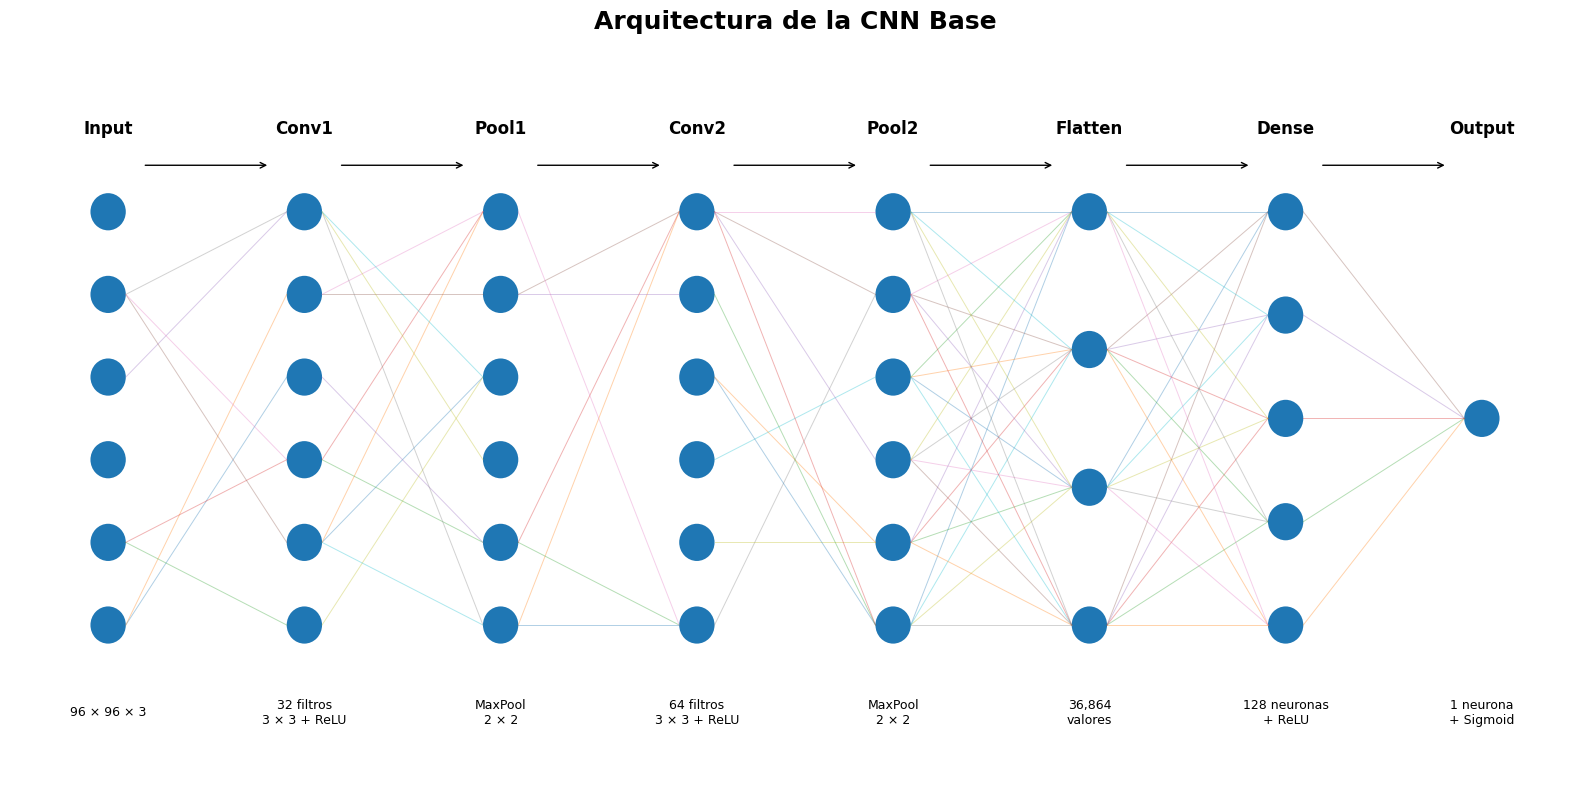

In [9]:
# Create figure
fig, ax = plt.subplots(figsize=(16, 8))

# Layer positions
layers = {
    "Input": 0,
    "Conv1": 2,
    "Pool1": 4,
    "Conv2": 6,
    "Pool2": 8,
    "Flatten": 10,
    "Dense": 12,
    "Output": 14
}

# Number of neurons/features shown for each layer
n_neurons = {
    "Input": 6,
    "Conv1": 6,
    "Pool1": 6,
    "Conv2": 6,
    "Pool2": 6,
    "Flatten": 4,
    "Dense": 5,
    "Output": 1
}

# Information shown below each layer
info = {
    "Input": "96 × 96 × 3",
    "Conv1": "32 filtros\n3 × 3 + ReLU",
    "Pool1": "MaxPool\n2 × 2",
    "Conv2": "64 filtros\n3 × 3 + ReLU",
    "Pool2": "MaxPool\n2 × 2",
    "Flatten": "36,864\nvalores",
    "Dense": "128 neuronas\n+ ReLU",
    "Output": "1 neurona\n+ Sigmoid"
}

# Draw layers
for name, x in layers.items():

    n = n_neurons[name]

    # Vertical positions
    if n == 1:
        ys = [3]
    else:
        ys = np.linspace(1, 5, n)

    # Draw neurons
    for y in ys:
        circle = Circle((x, y), 0.18)
        ax.add_patch(circle)

    # Connect to next layer
    names = list(layers.keys())
    current_index = names.index(name)

    if current_index < len(names) - 1:

        next_name = names[current_index + 1]
        next_x = layers[next_name]
        next_n = n_neurons[next_name]

        if next_n == 1:
            next_ys = [3]
        else:
            next_ys = np.linspace(1, 5, next_n)

        # Draw connections
        for y1 in ys:
            for y2 in next_ys:

                # Avoid drawing too many connections
                if len(ys) > 5 and len(next_ys) > 5:
                    if np.random.rand() > 0.25:
                        continue

                ax.plot(
                    [x + 0.18, next_x - 0.18],
                    [y1, y2],
                    linewidth=0.7,
                    alpha=0.35
                )

    # Layer name
    ax.text(
        x,
        5.8,
        name,
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

    # Layer information
    ax.text(
        x,
        0.15,
        info[name],
        ha="center",
        va="center",
        fontsize=9
    )

# Add arrows between major stages
for x1, x2 in zip(
    list(layers.values())[:-1],
    list(layers.values())[1:]
):
    ax.annotate(
        "",
        xy=(x2 - 0.35, 5.45),
        xytext=(x1 + 0.35, 5.45),
        arrowprops=dict(arrowstyle="->", linewidth=1)
    )

# Title
ax.set_title(
    "Arquitectura de la CNN Base",
    fontsize=18,
    fontweight="bold",
    pad=20
)

# Remove axes
ax.set_xlim(-1, 15)
ax.set_ylim(-0.5, 6.5)
ax.axis("off")

plt.tight_layout()
plt.show()

- Configuración de entrenamiento

Según la guía de la materia, existen diferentes funciones de pérdida que pueden utilizarse dependiendo del tipo de problema. En este caso, se seleccionó Binary Cross Entropy (BCE) debido a que el problema corresponde a una clasificación binaria, en la que el modelo debe distinguir entre pacientes con glaucoma y sin glaucoma. Esta función permite medir el error entre la probabilidad predicha por el modelo y la clase real, donde las etiquetas corresponden a 0 y 1.

Además de ello, se escogió Adam como optimizador, ya que este adapta la tasa de actualización de cada parámetro utilizando la información de los gradientes acumulada durante el entrenamiento. Esto permite ajustar los pesos de la red de manera adaptativa y puede favorecer una convergencia más estable durante el proceso de entrenamiento.


In [10]:
# Create the base model
set_seed()
modelo = redbasecnn(dropout_p=0.0).to(DEVICE)

# Loss function
criterion = nn.BCELoss()

# Optimizer
optimizer = torch.optim.Adam(
    modelo.parameters(),
    lr=1e-3
)

- Entrenar modelo base

In [11]:
EPOCHS = 20

train_losses = []
val_losses = []
train_accs = []
val_accs = []

t0 = time.perf_counter()

Epoch [01/20] Train Loss: 0.8518 | Val Loss: 0.5120 | Diff: -0.3397 | Train Acc: 0.7904 | Val Acc: 0.7969
Epoch [02/20] Train Loss: 0.5196 | Val Loss: 0.4805 | Diff: -0.0391 | Train Acc: 0.7904 | Val Acc: 0.7969
Epoch [03/20] Train Loss: 0.4958 | Val Loss: 0.4743 | Diff: -0.0215 | Train Acc: 0.7904 | Val Acc: 0.7969
Epoch [04/20] Train Loss: 0.4589 | Val Loss: 0.4411 | Diff: -0.0178 | Train Acc: 0.7978 | Val Acc: 0.8125
Epoch [05/20] Train Loss: 0.4215 | Val Loss: 0.4781 | Diff: 0.0566 | Train Acc: 0.8088 | Val Acc: 0.8125
Epoch [06/20] Train Loss: 0.4494 | Val Loss: 0.4389 | Diff: -0.0105 | Train Acc: 0.8051 | Val Acc: 0.7969
Epoch [07/20] Train Loss: 0.3786 | Val Loss: 0.4330 | Diff: 0.0544 | Train Acc: 0.8235 | Val Acc: 0.8281
Epoch [08/20] Train Loss: 0.3731 | Val Loss: 0.4741 | Diff: 0.1011 | Train Acc: 0.8162 | Val Acc: 0.8438
Epoch [09/20] Train Loss: 0.3482 | Val Loss: 0.4534 | Diff: 0.1051 | Train Acc: 0.8346 | Val Acc: 0.8281
Epoch [10/20] Train Loss: 0.3359 | Val Loss: 0.416

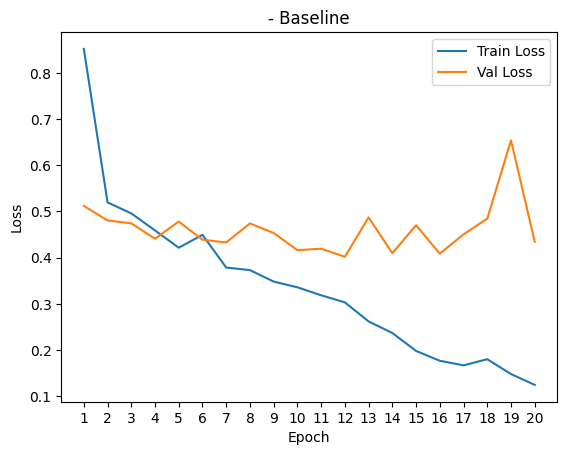

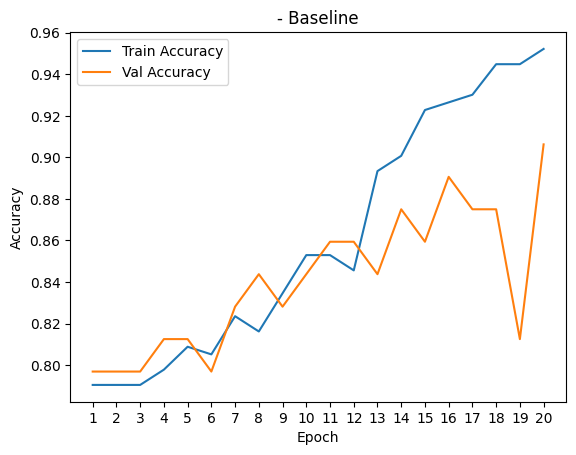

In [12]:
for epoch in range(EPOCHS):
    modelo.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()
        pred = modelo(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * xb.size(0)
        pred_class = (pred >= 0.5).float()
        train_correct += (pred_class == yb).sum().item()
        train_total += yb.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    modelo.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            pred = modelo(xb)
            loss = criterion(pred, yb)

            val_loss += loss.item() * xb.size(0)
            pred_class = (pred >= 0.5).float()
            val_correct += (pred_class == yb).sum().item()
            val_total += yb.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    loss_diff = val_loss - train_loss

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] "
          f"Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"Diff: {loss_diff:.4f} | "
          f"Train Acc: {train_acc:.4f} | "
          f"Val Acc: {val_acc:.4f}")

print(f"\n[Baseline {EPOCHS} ep] Wall time: {time.perf_counter() - t0:.1f}s")

baseline_history = {
    "train_loss": train_losses,
    "val_loss": val_losses,
    "train_acc": train_accs,
    "val_acc": val_accs
}

plot_history(baseline_history, title="- Baseline")

En este caso, se puede observar que, a lo largo de las épocas, el Train Loss disminuye de manera significativa, pasando de 0.8518 en la época 1 a 0.1246 en la época 20. Sin embargo, el Val Loss presenta un comportamiento más fluctuante y no disminuye de manera consistente. Aunque alcanza valores bajos en diferentes épocas, vuelve a aumentar en otros momentos, lo que genera una diferencia cada vez mayor respecto al entrenamiento.

Esta diferencia se evidencia especialmente en las últimas épocas. En la época 10, el Train Loss es de 0.3359, mientras que el Val Loss es de 0.4162. Posteriormente, en la época 20, el Train Loss disminuye hasta 0.1246, mientras que el Val Loss se encuentra en 0.4345. Esto muestra que el modelo continúa mejorando sobre los datos de entrenamiento, pero dicha mejora no se mantiene de la misma manera en los datos de validación.

Además, después de aproximadamente la época 12, la diferencia entre ambas pérdidas comienza a hacerse más evidente. Por ejemplo, en la época 12 el Train Loss es de 0.3032 y el Val Loss de 0.4019, mientras que en la época 18 la diferencia aumenta a aproximadamente 0.3042. En la época 19 se presenta una diferencia aún mayor, de 0.5058, debido principalmente al aumento del Val Loss hasta 0.6539.

Este comportamiento también se puede observar en las gráficas: la curva de Train Loss mantiene una tendencia descendente, mientras que la curva de Val Loss presenta fluctuaciones y deja de mejorar de forma consistente. Esto indica que el modelo continúa aprendiendo sobre el conjunto de entrenamiento, pero su desempeño sobre datos de validación no mejora al mismo ritmo.

Por otro lado, la Train Accuracy aumenta desde 79.04% hasta 95.22%, mientras que la Val Accuracy alcanza un máximo de 90.62% en la época 20. Aunque ambas métricas mejoran, existe una diferencia entre el desempeño sobre entrenamiento y validación, especialmente en las últimas épocas. En conjunto, este comportamiento es consistente con la presencia de sobreajuste, ya que el modelo obtiene una mejora considerable en entrenamiento mientras la pérdida de validación presenta fluctuaciones y no sigue la misma tendencia descendente.

## Problema detectado del modelo base

Se evidencia un posible sobreajuste, ya que el Train Loss disminuye hasta 0.1246 y la Train Accuracy aumenta hasta 95.22%, mientras que el Val Loss se mantiene fluctuante y alcanza 0.6539, y la Val Accuracy llega hasta 90.62%. Esto muestra que el modelo mejora en entrenamiento, pero no logra la misma mejora de manera consistente en validación. De acuerdo con los contenidos vistos en clase, este comportamiento es característico del sobreajuste, ya que existe una diferencia considerable entre el desempeño del modelo en entrenamiento y en validación.

Aggarwal, C. C. (2018). *Neural networks and deep learning: A textbook*. Springer. https://doi.org/10.1007/978-3-319-94463-0

# 4.Diseño Experimental

En este caso, se probarán distintas configuraciones de entrenamiento sobre la misma arquitectura, variando las técnicas de regularización, teniendo presente que estas buscan mejorar la capacidad de generalización del modelo y reducir el sobreajuste identificado en el modelo base. Sin embargo, no se parte de la idea de que una técnica sea mejor o peor que otra de manera absoluta, ya que su comportamiento depende de los datos, la arquitectura y la configuración utilizada. Por esta razón, se probarán diferentes alternativas y se compararán sus resultados.

Para realizar esta comparación, en lugar de fijar un único valor para cada técnica, se hará un barrido sistemático sobre diferentes valores de cada regularizador. En cada barrido se modificará un solo factor a la vez, manteniendo constante el resto de la configuración, como la arquitectura, la semilla, el número de épocas y el lr. De esta manera, se busca aislar el efecto de cada técnica y evitar una exploración aleatoria.

Los valores se definirán previamente a partir de rangos utilizados comúnmente en la práctica. Para L2 (weight_decay) se utilizará una grilla logarítmica entre 1e-5 y 1e-2; para Dropout, valores entre 0.2 y 0.7; y para Data Augmentation, tres niveles de intensidad creciente. Adicionalmente, se evalúan dos intervenciones de optimización (la tasa de aprendizaje y el algoritmo de optimización) y, finalmente, un diseño factorial que combina todas las técnicas para estudiar sus interacciones.

La selección de cada configuración se realizará utilizando el conjunto de validación, tomando como criterio el menor val_loss alcanzado durante el entrenamiento. El conjunto de test no se utilizará durante esta búsqueda, con el fin de mantenerlo como una evaluación final independiente.

Finalmente, se compararán el baseline, la mejor configuración encontrada para cada técnica y una configuración combinada, utilizando los mejores valores obtenidos individualmente. De esta manera, la elección se basa en la evidencia obtenida durante la experimentación y no en asumir previamente que una técnica es mejor que otra.

In [13]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    running_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if is_train else torch.no_grad()

    with context:
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            if is_train:
                optimizer.zero_grad()

            pred = model(xb)
            loss = criterion(pred, yb)

            if is_train:
                loss.backward()
                optimizer.step()

            running_loss += loss.item() * xb.size(0)
            pred_class = (pred >= 0.5).float()
            correct += (pred_class == yb).sum().item()
            total += yb.size(0)

    return running_loss / total, correct / total

In [14]:
class EarlyStopping:
    """Decide CUÁNDO detener el entrenamiento (activa `should_stop` si
    `val_loss` no mejora durante `patience` épocas consecutivas).

    Nota de diseño: esta clase YA NO guarda los pesos de la mejor época —
    eso ahora lo hace `fit()` SIEMPRE, para todas las corridas (con o sin
    Early Stopping), de modo que 'guardar el mejor checkpoint' y 'decidir
    parar antes de tiempo' sean dos responsabilidades independientes. Antes,
    solo las corridas CON `patience` restauraban el mejor checkpoint; las de
    Baseline/L2/Dropout/Augmentation quedaban con los pesos de la última
    época (ya sobreajustados), haciendo la comparación final injusta.
    """

    def __init__(self, patience: int = 5, min_delta: float = 1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.should_stop = False

    def step(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True


In [15]:
# fit() corregido: SIEMPRE guarda y restaura los pesos de la época con mejor
# val_loss, corra o no Early Stopping. Antes solo lo hacía cuando se pasaba
# `early_stopping`, lo que hacía que Baseline/L2/Dropout/Augmentation se
# evaluaran en test con los pesos de la última época (ya sobreajustados),
# mientras Early Stopping/Combinado sí usaban su mejor checkpoint -> la
# comparación final no era una comparación justa entre técnicas.
def fit(model, train_loader, val_loader, epochs, lr, weight_decay=0.0,
        criterion=None, early_stopping=None, restore_best=True, verbose=True,
        optimizer_name="adam", momentum=0.9):
    if criterion is None:
        criterion = nn.BCELoss()

    # Optimizador configurable (por defecto Adam, igual que en todos los barridos previos,
    # por lo que los resultados anteriores no cambian).
    if optimizer_name == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_name == "sgd":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum,
                                    weight_decay=weight_decay)
    elif optimizer_name == "rmsprop":
        optimizer = torch.optim.RMSprop(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError(f"Optimizador no soportado: {optimizer_name}")
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    best_loss = float("inf")
    best_epoch = 0
    best_state = None

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # Checkpoint del mejor punto (independiente de si hay early stopping o no)
        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

        if verbose:
            print(f"Epoch {epoch+1:3d}/{epochs} | "
                  f"train_loss={train_loss:.4f} train_acc={train_acc:.3f} | "
                  f"val_loss={val_loss:.4f} val_acc={val_acc:.3f}")

        if early_stopping is not None:
            early_stopping.step(val_loss)
            if early_stopping.should_stop:
                if verbose:
                    print(f"-> Early stopping activado en la época {epoch+1} "
                          f"(mejor época: {best_epoch + 1}, mejor val_loss: {best_loss:.4f})")
                break

    if restore_best and best_state is not None:
        model.load_state_dict(best_state)

    history["best_epoch"] = best_epoch
    return model, history


In [16]:
def run_single_config(dropout_p=0.0, weight_decay=0.0, transform_train=None,
                       epochs=20, patience=None, lr=1e-3, verbose=False,
                       optimizer_name="adam"):
    if transform_train is None:
        transform_train = base_resize

    set_seed(BASE_SEED)
    tr_loader, va_loader, te_loader = make_loaders(transform_train=transform_train)

    model = redbasecnn(dropout_p=dropout_p).to(DEVICE)
    criterion = nn.BCELoss()
    es = EarlyStopping(patience=patience) if patience is not None else None

    model, history = fit(model, tr_loader, va_loader, epochs=epochs, lr=lr,
                          weight_decay=weight_decay, criterion=criterion,
                          early_stopping=es, verbose=verbose,
                          optimizer_name=optimizer_name)

    test_loss, test_acc = run_epoch(model, te_loader, criterion, optimizer=None)
    return model, history, {"test_loss": test_loss, "test_acc": test_acc}


def resumen_sweep(sweep_dict, value_label="valor"):
    """Imprime una tabla corta con el resultado de cada punto de un barrido."""
    for val, r in sweep_dict.items():
        n_ep = len(r["history"]["train_loss"])
        print(f"{value_label}={val!s:<10} | épocas={n_ep:3d} | "
              f"best_val_loss={min(r['history']['val_loss']):.4f} | "
              f"best_val_acc={max(r['history']['val_acc']):.4f} | "
              f"test_acc={r['test_acc']:.4f}")

- Pipeline de data augmentation

En este caso se aplica únicamente sobre el conjunto de entrenamiento. En vez de un solo pipeline fijo, se define tres niveles de intensidad creciente, para tratar la intensidad de augmentation con una variable más a barrer, lo mismo que se hace en l2 con lambda o en dropout con p, en vez de elegir un único pipeline arbitrario.

In [17]:
transform_light = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
])

transform_moderate = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
])

transform_strong = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
])

AUG_CANDIDATES = {
    "Sin augmentation": base_resize,
    "Leve": transform_light,
    "Moderada": transform_moderate,
    "Fuerte": transform_strong,
}

## Barrido 1: Regularización L2

Se utiliza una grilla logarítmica estándar, incluyendo lambda=0.0 como punto de referencia. Este valor corresponde al baseline, ya que se mantiene la misma arquitectura, pero sin aplicar regularización.

Hipótesis: Si se incrementa el valor de lambda (weight_decay), se espera que se penalice la magnitud de los pesos y se reduzca el sobreajuste, mejorando el Val Loss respecto al baseline.


In [18]:
SWEEP_EPOCHS = 40  # más margen que las 20 del modelo base, para ver el efecto completo
L2_CANDIDATES = [0.0, 1e-5, 1e-4, 1e-3, 1e-2]

l2_sweep = {}
t0 = time.perf_counter()
for lam in L2_CANDIDATES:
    model, history, test_metrics = run_single_config(
        weight_decay=lam, epochs=SWEEP_EPOCHS
    )
    l2_sweep[lam] = {"model": model, "history": history, **test_metrics}

resumen_sweep(l2_sweep, value_label="lambda")
print(f"\n[Barrido L2] Wall time: {time.perf_counter() - t0:.1f}s")

best_lambda = min(l2_sweep, key=lambda k: min(l2_sweep[k]["history"]["val_loss"]))
print(f"\nMejor lambda según val_loss: {best_lambda}")


lambda=0.0        | épocas= 40 | best_val_loss=0.3487 | best_val_acc=0.9375 | test_acc=0.7976
lambda=1e-05      | épocas= 40 | best_val_loss=0.3537 | best_val_acc=0.9531 | test_acc=0.7976
lambda=0.0001     | épocas= 40 | best_val_loss=0.3558 | best_val_acc=0.9531 | test_acc=0.8095
lambda=0.001      | épocas= 40 | best_val_loss=0.3512 | best_val_acc=0.9219 | test_acc=0.8333
lambda=0.01       | épocas= 40 | best_val_loss=0.3513 | best_val_acc=0.8906 | test_acc=0.7976

[Barrido L2] Wall time: 27.9s

Mejor lambda según val_loss: 0.0


## Barrido 2: Dropout

En este caso se utilizarán valores como 0.0, 0.2, 0.3, 0.5 y 0.7, teniendo presente que en la técnica de Dropout, p representa la probabilidad de desactivar aleatoriamente una neurona durante el entrenamiento. Por ejemplo, un valor de p=0.2 indica que se desactivará el 20 % de las neuronas seleccionadas en cada aplicación de la técnica, mientras que el 80 % restante continuará activo.

El valor p=0.0 implica que no se desactivan neuronas, por lo que no se aplica Dropout. Por su parte, valores más altos, como p=0.5 o p=0.7, representan una mayor proporción de neuronas desactivadas, lo que puede ayudar a reducir el sobreajuste, aunque también podría dificultar el aprendizaje si la probabilidad es demasiado elevada.


Hipótesis: Si se incrementa la probabilidad p de Dropout, se espera reducir la co-adaptación entre neuronas y, con ello, el sobreajuste, mejorando el Val Loss.

In [19]:
DROPOUT_CANDIDATES = [0.0, 0.2, 0.3, 0.5, 0.7]

dropout_sweep = {}
t0 = time.perf_counter()
for p in DROPOUT_CANDIDATES:
    model, history, test_metrics = run_single_config(
        dropout_p=p, epochs=SWEEP_EPOCHS
    )
    dropout_sweep[p] = {"model": model, "history": history, **test_metrics}

resumen_sweep(dropout_sweep, value_label="dropout_p")
print(f"\n[Barrido Dropout] Wall time: {time.perf_counter() - t0:.1f}s")

best_dropout = min(dropout_sweep, key=lambda k: min(dropout_sweep[k]["history"]["val_loss"]))
print(f"\nMejor dropout_p según val_loss: {best_dropout}")


dropout_p=0.0        | épocas= 40 | best_val_loss=0.3487 | best_val_acc=0.9375 | test_acc=0.7976
dropout_p=0.2        | épocas= 40 | best_val_loss=0.3853 | best_val_acc=0.9219 | test_acc=0.7143
dropout_p=0.3        | épocas= 40 | best_val_loss=0.3676 | best_val_acc=0.9062 | test_acc=0.7619
dropout_p=0.5        | épocas= 40 | best_val_loss=0.3768 | best_val_acc=0.8906 | test_acc=0.7738
dropout_p=0.7        | épocas= 40 | best_val_loss=0.3809 | best_val_acc=0.9219 | test_acc=0.8571

[Barrido Dropout] Wall time: 27.5s

Mejor dropout_p según val_loss: 0.0


En este caso, la hipótesis no se cumplió. Ninguno de los valores de Dropout probados (p = 0.2, 0.3, 0.5 y 0.7) logró mejorar el Val Loss respecto al modelo sin Dropout (0.3487), por lo que el mejor valor del barrido fue p = 0.0, que corresponde al baseline. Entre los valores mayores a cero, el mejor fue p = 0.3 (0.3676), pero aun así quedó 0.019 por encima del baseline.

Además, el efecto no fue monótono ya que con p = 0.2 obtuvo el peor Val Loss (0.3853), mientras que p = 0.3 fue el mejor de los valores con Dropout. Esto indica que no existe una relación clara del tipo "a mayor p, menor sobreajuste" en este modelo, y que las diferencias entre los valores de p son pequeñas y pueden estar influenciadas por el azar del entrenamiento, dado el tamaño reducido del conjunto de validación (64 imágenes).

Una posible explicación es que la red es relativamente pequeña y se entrena con solo 272 imágenes. Al apagar neuronas de forma aleatoria, se reduce la capacidad que el modelo tiene para aprender los patrones útiles de las imágenes, y no solamente su capacidad de memorizar ruido. También hay que tener en cuenta que en esta arquitectura el Dropout se aplica únicamente después de la capa densa de 128 neuronas, por lo que no regulariza las capas convolucionales, que son las encargadas de extraer las características de las imágenes.

Por otro lado, aunque p = 0.7 obtuvo el mayor Test Acc (0.8571), no se considera la mejor configuración, ya que la selección se realiza con el Val Loss, donde fue uno de los peores valores, y el conjunto de test no se utiliza para tomar decisiones.

## Barrido 3: Intensidad de data augmentation

En este caso para ver el efecto de data augmentation, se compara "Sin augmentation" con tres niveles de intensidad definidos arriba.

Hipótesis: Si se incrementa la intensidad del data augmentation, se espera dificultar la memorización de detalles específicos del set de entrenamiento y mejorar el Val Loss, aunque en niveles muy altos podría distorsionar información clínicamente relevante del disco óptico.

In [20]:
aug_sweep = {}
t0 = time.perf_counter()
for name, tfm in AUG_CANDIDATES.items():
    model, history, test_metrics = run_single_config(
        transform_train=tfm, epochs=SWEEP_EPOCHS
    )
    aug_sweep[name] = {"model": model, "history": history, **test_metrics}

resumen_sweep(aug_sweep, value_label="augmentation")
print(f"\n[Barrido Augmentation] Wall time: {time.perf_counter() - t0:.1f}s")

best_aug = min(aug_sweep, key=lambda k: min(aug_sweep[k]["history"]["val_loss"]))
print(f"\nMejor nivel de augmentation según val_loss: {best_aug}")


augmentation=Sin augmentation | épocas= 40 | best_val_loss=0.3487 | best_val_acc=0.9375 | test_acc=0.7976
augmentation=Leve       | épocas= 40 | best_val_loss=0.2907 | best_val_acc=0.9219 | test_acc=0.7381
augmentation=Moderada   | épocas= 40 | best_val_loss=0.3129 | best_val_acc=0.9219 | test_acc=0.8214
augmentation=Fuerte     | épocas= 40 | best_val_loss=0.4119 | best_val_acc=0.8438 | test_acc=0.7976

[Barrido Augmentation] Wall time: 47.0s

Mejor nivel de augmentation según val_loss: Leve



En este caso, la hipótesis se cumplió. Data Augmentation fue la única de las técnicas de regularización (L2, Dropout y Augmentation) que logró mejorar el Val Loss respecto al baseline. El nivel Leve redujo el mejor Val Loss de 0.3487 a 0.2907, una mejora de aproximadamente 17%, y el nivel Moderado también mejoró el resultado (0.3129).

Sin embargo, la relación entre la intensidad y el desempeño no es lineal. A medida que aumenta la intensidad, el Val Loss empeora ya que pasa de 0.2907 (Leve) a 0.3129 (Moderada) y a 0.4119 (Fuerte), este último peor que no aplicar augmentation. En el nivel Fuerte, además, el Val Acc bajó a 0.8438, el valor más bajo del barrido. Esto indica que, pasado cierto punto, las transformaciones dejan de combatir el sobreajuste y empiezan a generar subajuste, debido a las rotaciones de ±20°, la traslación y los cambios agresivos de color probablemente distorsionan rasgos clínicamente relevantes del disco óptico, como su forma, su posición y el contraste entre el disco y la excavación, que son justamente los que permiten diferenciar un ojo sano de uno con glaucoma.


Por otro lado, el nivel Leve obtuvo un Test Acc menor (0.7381) que el baseline (0.7976). Con un conjunto de prueba de solo 84 imágenes, esta diferencia corresponde a 5 imágenes mal clasificadas, por lo que no debe sobreinterpretarse. Además, al observar la curva de validación del nivel Leve, su mejor Val Loss (época 30) corresponde a un valor puntual más bajo que el de las épocas cercanas, por lo que parte de la mejora podría deberse a la variabilidad propia de un conjunto de validación pequeño. Aun así, el nivel Moderado también mejoró el Val Loss y obtuvo un Test Acc mayor al baseline (0.8214), lo que refuerza la idea de que una augmentation de baja o media intensidad sí ayuda a generalizar.

Es interesante que el mejor nivel sea el más simple, que solo aplica un volteo horizontal. Esta transformación tiene sentido para este tipo de imágenes, ya que voltear horizontalmente la imagen de un ojo derecho produce una imagen muy similar a la de un ojo izquierdo, es decir, genera variaciones anatómicamente realistas sin alterar las características del disco óptico.

Finalmente, el diseño factorial (Barrido 7) confirmó este resultado: Data Augmentation fue la técnica con mayor efecto positivo y la más consistente, ya que redujo en promedio el Val Loss con SGD + momentum (−0.047) y con Adam (−0.030), y las 10 mejores configuraciones de las 48 evaluadas incluyen Augmentation.


## Barrido 4: Paciencia de Early Stopping

En el libro Neural Networks and Deep Learning se presenta el Early Stopping como otro de los métodos utilizados para la regularización. Aunque podría parecer que no cumple esta función, debido a que no modifica directamente los pesos ni los parámetros de la red neuronal, su objetivo consiste en detener el entrenamiento antes de que comience el sobreajuste (overfitting).

Este método se considera un regularizador porque limita el tiempo de entrenamiento y, por tanto, restringe el conjunto de parámetros que el modelo puede alcanzar durante el proceso de optimización. Generalmente, se monitorea el error sobre el conjunto de validación y se detiene el entrenamiento cuando este deja de mejorar, evitando que el modelo continúe ajustándose excesivamente a los datos de entrenamiento.

Aggarwal, C. C. (2018). *Neural networks and deep learning: A textbook*. Springer. https://doi.org/10.1007/978-3-319-94463-0


Hipótesis: Si se detiene el entrenamiento cuando el Val Loss deja de mejorar durante "patience" épocas, se espera evitar la región de sobreajuste tardío sin modificar directamente los pesos del modelo.

In [21]:
ES_EPOCHS = 60  # más margen para que distintas paciencias tengan oportunidad de diferenciarse
PATIENCE_CANDIDATES = [3, 5, 10]

es_sweep = {}
t0 = time.perf_counter()
for pat in PATIENCE_CANDIDATES:
    model, history, test_metrics = run_single_config(
        epochs=ES_EPOCHS, patience=pat
    )
    es_sweep[pat] = {"model": model, "history": history, **test_metrics}

resumen_sweep(es_sweep, value_label="patience")
print(f"\n[Barrido Early Stopping] Wall time: {time.perf_counter() - t0:.1f}s")

best_patience = min(es_sweep, key=lambda k: min(es_sweep[k]["history"]["val_loss"]))
print(f"\nMejor patience según val_loss: {best_patience}")


patience=3          | épocas=  6 | best_val_loss=0.4369 | best_val_acc=0.8281 | test_acc=0.7619
patience=5          | épocas= 22 | best_val_loss=0.3487 | best_val_acc=0.9375 | test_acc=0.7976
patience=10         | épocas= 27 | best_val_loss=0.3487 | best_val_acc=0.9375 | test_acc=0.7976

[Barrido Early Stopping] Wall time: 8.5s

Mejor patience según val_loss: 5


Con patience = 3, el entrenamiento se detuvo demasiado pronto, en la época 6, antes de que el modelo alcanzara a aprender los patrones de las imágenes. Por eso su Val Loss con un valor de 0.4369 y su Val Acc con un valor de 0.8281 son los peores del barrido; en este caso la detención temprana no evitó el sobreajuste, sino que produjo subajuste. Esto ocurre porque la curva de validación del modelo base es bastante oscilante ya que basta con que el Val Loss no mejore durante tres épocas seguidas para que el entrenamiento se detenga, aunque el modelo todavía pudiera seguir mejorando.

Con patience = 5 y patience = 10, el entrenamiento se detuvo en las épocas 22 y 27, respectivamente, y ambos alcanzaron exactamente el mismo mejor Val Loss (0.3487), que además es igual al del baseline sin Early Stopping. Esto se debe a que en los tres casos el mínimo de validación se alcanza en la misma época (la 17), y la función de entrenamiento siempre restaura los pesos de la mejor época. Por lo tanto, las tres configuraciones terminan con el mismo modelo y el mismo desempeño en test (0.7976). Se seleccionó patience = 5 porque, ante el empate en Val Loss, es la opción más eficiente ya que necesita menos épocas.

Por lo tanto, la hipótesis se cumple solo parcialmente. Early Stopping sí evita la región de sobreajuste tardío, en el baseline, después de la época 20 el Val Loss sube hasta aproximadamente 0.63 mientras el Train Loss sigue bajando, y con patience = 5 el entrenamiento se detiene en la época 22, antes de entrar en esa zona. Sin embargo, como el mejor modelo ya se recupera siempre mediante la restauración del mejor checkpoint, Early Stopping no mejora la generalización del modelo final. Su aporte principal es la eficiencia: con patience = 5 se obtiene el mismo resultado entrenando 22 épocas en lugar de 40, es decir, aproximadamente un 45% menos de entrenamiento.

## Barrido 5: Optimización — tasa de aprendizaje (learning rate)

Los cuatro barridos anteriores se enfocan en la generalización, es decir, en aplicar regularización al modelo. En este caso, el barrido se enfoca en la optimización, específicamente en la tasa de aprendizaje de Adam (`lr`). Esta variable controla qué tan grandes son los pasos que se realizan al actualizar los pesos y, por lo tanto, influye en la velocidad y estabilidad con la que el modelo converge.

Para este experimento se mantiene todo lo demás fijo, tanto, la arquitectura, la semilla 42, sin L2, sin Dropout, sin augmentation y 40 épocas. La única variable que cambia es `lr`. El valor `1e-3` corresponde al baseline. Al igual que en los demás barridos, el valor seleccionado se determina usando el menor **Val Loss**, sin utilizar el conjunto de test para tomar esta decisión.

**Hipótesis:** al disminuir la tasa de aprendizaje, los cambios en los pesos serán más pequeños, por lo que la curva de Val Loss debería ser más estable, aunque la convergencia puede ser más lenta. Por el contrario, al aumentar `lr`, el modelo puede acercarse más rápido al mínimo, pero también puede presentar mayores oscilaciones o incluso inestabilidad debido a que los pasos son demasiado grandes.

* **Variable independiente:** `lr` ∈ {1e-4, 5e-4, 1e-3, 3e-3}
* **Variables controladas:** arquitectura, semilla, partición de los datos, 40 épocas, optimizador Adam y batch size de 32.
* **Criterio de éxito:** obtener un menor Val Loss que el baseline con un valor de 0.3487 y/o una curva de validación más estable, sin empeorar el desempeño en test.

Además del Val Loss, en este barrido se analizan dos indicadores relacionados con la convergencia, uno de ellos es la época en la que se obtiene el mejor Val Loss, para evaluar la velocidad de convergencia, y la oscilación de la curva de validación, calculada mediante la desviación estándar de los cambios de Val Loss entre épocas consecutivas.


In [22]:
LR_CANDIDATES = [1e-4, 5e-4, 1e-3, 3e-3]   # 1e-3 = baseline

lr_sweep = {}
t0 = time.perf_counter()
for lr_val in LR_CANDIDATES:
    model, history, test_metrics = run_single_config(
        lr=lr_val, epochs=SWEEP_EPOCHS
    )
    lr_sweep[lr_val] = {"model": model, "history": history, **test_metrics}

resumen_sweep(lr_sweep, value_label="lr")
print(f"\n[Barrido Learning Rate] Wall time: {time.perf_counter() - t0:.1f}s")

best_lr = min(lr_sweep, key=lambda k: min(lr_sweep[k]["history"]["val_loss"]))
print(f"\nMejor lr según val_loss: {best_lr}")


lr=0.0001     | épocas= 40 | best_val_loss=0.3808 | best_val_acc=0.8906 | test_acc=0.7857
lr=0.0005     | épocas= 40 | best_val_loss=0.3472 | best_val_acc=0.9375 | test_acc=0.7738
lr=0.001      | épocas= 40 | best_val_loss=0.3487 | best_val_acc=0.9375 | test_acc=0.7976
lr=0.003      | épocas= 40 | best_val_loss=0.3942 | best_val_acc=0.9219 | test_acc=0.8571

[Barrido Learning Rate] Wall time: 21.5s

Mejor lr según val_loss: 0.0005


,Época mejor Val Loss,Mejor Val Loss,Train Loss final,Oscilación Val Loss,Gap en mejor época (val-train),Test Acc
lr=0.0001,33.0,0.3808,0.1671,0.0181,0.1443,0.7857
lr=0.0005,21.0,0.3472,0.0060,0.0322,0.2623,0.7738
lr=0.001,17.0,0.3487,0.0052,0.0691,0.1927,0.7976
lr=0.003,17.0,0.3942,0.6952,0.2830,0.0591,0.8571


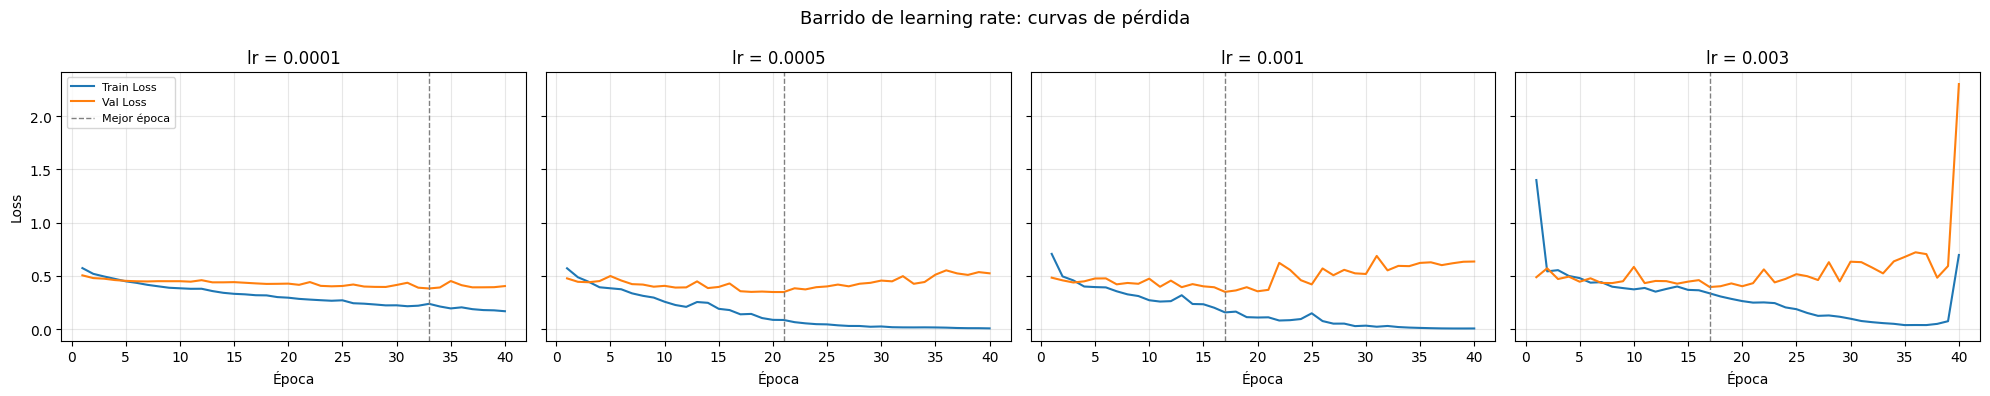

In [23]:
# --- Indicadores de convergencia por learning rate ---
def convergence_stats(history):
    vl = np.array(history["val_loss"])
    tl = np.array(history["train_loss"])
    best_ep = int(np.argmin(vl))
    return {
        "Época mejor Val Loss": best_ep + 1,                          # velocidad
        "Mejor Val Loss": round(vl.min(), 4),
        "Train Loss final": round(tl[-1], 4),
        "Oscilación Val Loss": round(np.std(np.diff(vl)), 4),        # estabilidad
        "Gap en mejor época (val-train)": round(vl[best_ep] - tl[best_ep], 4),
    }

lr_df = pd.DataFrame({f"lr={k}": {**convergence_stats(r["history"]),
                                   "Test Acc": round(r["test_acc"], 4)}
                      for k, r in lr_sweep.items()}).T
display(lr_df)

# --- Curvas de Train/Val Loss por learning rate ---
fig, axes = plt.subplots(1, len(LR_CANDIDATES), figsize=(5 * len(LR_CANDIDATES), 4), sharey=True)
for ax, (lr_val, r) in zip(axes, lr_sweep.items()):
    h = r["history"]
    ep = range(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], label="Train Loss")
    ax.plot(ep, h["val_loss"], label="Val Loss")
    ax.axvline(h["best_epoch"] + 1, ls="--", color="gray", lw=1, label="Mejor época")
    ax.set_title(f"lr = {lr_val}")
    ax.set_xlabel("Época")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)
plt.suptitle("Barrido de learning rate: curvas de pérdida", fontsize=13)
plt.tight_layout()
plt.show()


En este caso nos podemos dar cuenta cómo es que los resultados, confirman la hipótesis que planteamos al inicio:

* **Velocidad de convergencia.** Con `lr = 1e-4` el modelo converge mucho más lento, ya que alcanza su mejor Val Loss hasta la época 33, mientras que con `lr = 1e-3` lo alcanza en la época 17. Además, al terminar las 40 épocas, el Train Loss con `lr = 1e-4` sigue en 0.167, lo que muestra que el modelo todavía no ha terminado de ajustarse.

* **Estabilidad.** La oscilación de la curva de validación aumenta a medida que aumenta el learning rate: 0.018, 0.032, 0.069 y 0.283. Esto se hace especialmente evidente con `lr = 3e-3`, donde el entrenamiento se vuelve inestable. En la última época, el Val Loss sube aproximadamente a 2.3 y el Train Loss a 0.70, lo que indica que los pasos son demasiado grandes y el modelo termina alejándose del mínimo que había encontrado.

* **Generalización.** El menor Val Loss se obtiene con `lr = 5e-4`, con un valor de 0.3472. Sin embargo, la diferencia frente al baseline (`lr = 1e-3`, Val Loss = 0.3487) es de solo 0.0015, por lo que no representa una mejora relevante con solo 64 imágenes de validación. Además, en la gráfica se observa que con `lr = 5e-4` y `lr = 1e-3` el Val Loss vuelve a aumentar después de alcanzar su mínimo, mientras el Train Loss continúa disminuyendo hasta acercarse a 0. Esto muestra el mismo patrón de sobreajuste observado en el modelo base. Con `lr = 1e-4` el sobreajuste parece menor, pero principalmente porque el modelo aprende más lentamente.

En conclusión podemos decir que la tasa de aprendizaje afecta principalmente la velocidad y estabilidad de la convergencia, pero por sí sola no soluciona el sobreajuste. El valor del baseline (`1e-3`) se encuentra en una zona adecuada: reducirlo a `5e-4` no genera una mejora relevante y aumentarlo a `3e-3` hace que el entrenamiento sea inestable. Aunque `lr = 3e-3` obtuvo el mayor Test Acc con un valor de 0.857, este resultado no se utiliza para seleccionar la configuración, ya que la elección se realiza con el Val Loss y el conjunto de test con 84 imágenes se mantiene únicamente para la evaluación final.


## Barrido 6: Optimización — algoritmo de optimización

Este barrido compara diferentes algoritmos para actualizar los pesos de la red, manteniendo todo lo demás fijo, es decir, arquitectura, semilla 42, sin L2, sin Dropout, sin augmentation, 40 épocas y batch size de 32. Adam con `lr = 1e-3` corresponde al baseline.

Cada optimizador funciona mejor con diferentes tasas de aprendizaje. Por eso no sería adecuado usar el mismo `lr` para todos, ya que alguno podría parecer peor simplemente por estar mal configurado. Por ejemplo, SGD con `lr = 1e-3` aprendería mucho más lento que con una tasa de `1e-2`. Por esta razón, en lugar de fijar un único valor, primero se realiza un **barrido de tasas de aprendizaje para cada optimizador**, y luego se comparan los optimizadores, cada uno con **su mejor `lr` según el Val Loss**. De esta manera, la comparación refleja el comportamiento del algoritmo y no una mala elección del tamaño de paso.

| Optimizador          | Valores de lr evaluados        | Funcionamiento                                                                                                         |
| -------------------- | ------------------------------ | ---------------------------------------------------------------------------------------------------------------------- |
| SGD + momentum (0.9) | `1e-3`, `3e-3`, `1e-2`, `3e-2`, `1e-1` | Usa un paso similar para los parámetros y el momentum ayuda a mantener la dirección de las actualizaciones anteriores. |
| RMSprop              | `1e-5`, `3e-5`, `1e-4`, `3e-4` | Ajusta el tamaño del paso de cada parámetro según el comportamiento reciente de sus gradientes.                        |
| Adam (baseline)      | `1e-4`, `5e-4`, `1e-3`, `3e-3` | Combina el efecto del momentum con un ajuste adaptativo del tamaño del paso. (Se reutilizan los resultados del Barrido 5.) |

Los rangos se eligieron alrededor de los valores que se usan habitualmente para cada optimizador, en una escala aproximadamente logarítmica.

**Nota sobre RMSprop:** en una primera prueba con `lr = 1e-3`, RMSprop tuvo un comportamiento inestable desde la primera época. La pérdida quedó fija en 20.31 durante todo el entrenamiento y el modelo terminó prediciendo "sano" para todas las imágenes, obteniendo un Val Acc de 0.797, que corresponde aproximadamente a la proporción de la clase mayoritaria.

El valor de 20.31 se puede relacionar con la proporción de imágenes de glaucoma en validación (≈ 0.203) y el límite de 100 que aplica `BCELoss` cuando `-log(p)` crece demasiado (0.203 × 100 ≈ 20.3). En este caso, la sigmoide terminó saturándose cerca de `p = 0`, haciendo que el gradiente prácticamente desapareciera y evitando que la red pudiera recuperarse.

Esto muestra que RMSprop es bastante sensible a la tasa de aprendizaje en este modelo. Por esta razón, su barrido se ubica en valores más bajos (`1e-5` a `3e-4`), para evaluarlo en una zona donde pueda entrenar correctamente y no simplemente medir el efecto de una tasa de aprendizaje demasiado alta.

**Hipótesis:** se espera que los optimizadores adaptativos, como Adam y RMSprop, converjan más rápido durante las primeras épocas que SGD + momentum, ya que pueden ajustar el tamaño del paso para cada parámetro. SGD + momentum podría necesitar más épocas para converger, aunque su trayectoria podría ser más suave y presentar una menor diferencia entre el entrenamiento y la validación.

* **Variable independiente:** optimizador, cada uno evaluado con su mejor tasa de aprendizaje dentro de su barrido.
* **Variables controladas:** arquitectura, semilla, partición de los datos, 40 épocas, batch size de 32 y ausencia de regularización.
* **Criterio de selección:** para cada optimizador se elige el `lr` con menor Val Loss; luego se comparan los optimizadores con ese mismo criterio. El conjunto de test no se utiliza en ninguna de estas decisiones.
* **Criterio de éxito:** obtener un menor Val Loss que el baseline (0.3487) y/o una curva de validación más estable. También se utilizan los mismos indicadores de convergencia del barrido anterior: la época en la que se alcanza el mejor Val Loss y la oscilación de la curva de validación.



=== SGD+momentum ===
lr=0.001      | épocas= 40 | best_val_loss=0.4501 | best_val_acc=0.8594 | test_acc=0.7976
lr=0.003      | épocas= 40 | best_val_loss=0.4088 | best_val_acc=0.8594 | test_acc=0.8571
lr=0.01       | épocas= 40 | best_val_loss=0.3846 | best_val_acc=0.9062 | test_acc=0.7024
lr=0.03       | épocas= 40 | best_val_loss=0.3419 | best_val_acc=0.8750 | test_acc=0.7619
lr=0.1        | épocas= 40 | best_val_loss=0.4753 | best_val_acc=0.8125 | test_acc=0.7976

=== RMSprop ===
lr=1e-05      | épocas= 40 | best_val_loss=0.4431 | best_val_acc=0.8281 | test_acc=0.7976
lr=3e-05      | épocas= 40 | best_val_loss=0.4211 | best_val_acc=0.8594 | test_acc=0.8333
lr=0.0001     | épocas= 40 | best_val_loss=0.3575 | best_val_acc=0.8906 | test_acc=0.8214
lr=0.0003     | épocas= 40 | best_val_loss=0.3843 | best_val_acc=0.9375 | test_acc=0.8333

=== Adam ===
lr=0.0001     | épocas= 40 | best_val_loss=0.3808 | best_val_acc=0.8906 | test_acc=0.7857
lr=0.0005     | épocas= 40 | best_val_loss=0.34

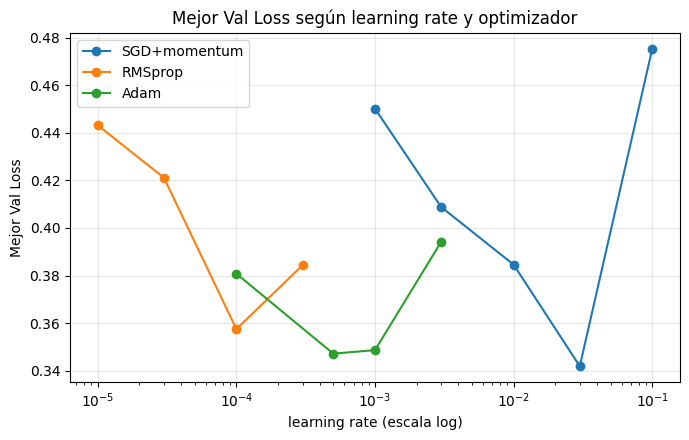

In [24]:
# --- Barrido de learning rate POR optimizador ---
# Cada optimizador trabaja bien en un rango distinto de lr, así que para compararlos
# de forma justa se busca el mejor lr de cada uno (según val_loss) y luego se
# comparan los optimizadores, cada uno con su mejor lr.
LR_GRID = {
    "SGD+momentum": [1e-3, 3e-3, 1e-2, 3e-2, 1e-1],
    "RMSprop":      [1e-5, 3e-5, 1e-4, 3e-4],
    "Adam":         LR_CANDIDATES,        # ya corrido en el Barrido 5 (se reutiliza)
}
OPT_NAME = {"SGD+momentum": "sgd", "RMSprop": "rmsprop", "Adam": "adam"}

opt_lr_sweep = {}      # opt_lr_sweep[optimizador][lr] = resultado
t0 = time.perf_counter()
for opt_name, grid in LR_GRID.items():
    opt_lr_sweep[opt_name] = {}
    for lr_val in grid:
        if opt_name == "Adam" and lr_val in lr_sweep:
            opt_lr_sweep[opt_name][lr_val] = lr_sweep[lr_val]      # mismo resultado, no se repite
            continue
        model, history, test_metrics = run_single_config(
            optimizer_name=OPT_NAME[opt_name], lr=lr_val, epochs=SWEEP_EPOCHS
        )
        opt_lr_sweep[opt_name][lr_val] = {"model": model, "history": history, **test_metrics}
    print(f"\n=== {opt_name} ===")
    resumen_sweep(opt_lr_sweep[opt_name], value_label="lr")
print(f"\n[Barrido lr x optimizador] Wall time: {time.perf_counter() - t0:.1f}s")

# --- Mejor lr de cada optimizador ---
OPT_CANDIDATES = {}
opt_sweep = {}
for opt_name, runs in opt_lr_sweep.items():
    best_lr_opt = min(runs, key=lambda k: min(runs[k]["history"]["val_loss"]))
    OPT_CANDIDATES[opt_name] = {"optimizer_name": OPT_NAME[opt_name], "lr": best_lr_opt}
    opt_sweep[opt_name] = runs[best_lr_opt]
    print(f"Mejor lr para {opt_name}: {best_lr_opt} "
          f"(val_loss={min(runs[best_lr_opt]['history']['val_loss']):.4f})")

best_opt = min(opt_sweep, key=lambda k: min(opt_sweep[k]["history"]["val_loss"]))
print(f"\nMejor optimizador (cada uno con su mejor lr) según val_loss: {best_opt}")

# --- Figura: Mejor Val Loss vs lr para cada optimizador ---
plt.figure(figsize=(7, 4.5))
for opt_name, runs in opt_lr_sweep.items():
    xs = list(runs.keys())
    ys = [min(runs[k]["history"]["val_loss"]) for k in xs]
    plt.plot(xs, ys, marker="o", label=opt_name)
plt.xscale("log")
plt.ylim(top=min(1.0, plt.ylim()[1]))   # por si alguna corrida diverge
plt.xlabel("learning rate (escala log)")
plt.ylabel("Mejor Val Loss")
plt.title("Mejor Val Loss según learning rate y optimizador")
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

,Época mejor Val Loss,Mejor Val Loss,Train Loss final,Oscilación Val Loss,Gap en mejor época (val-train),Test Acc
SGD+momentum (lr=0.03),17.0,0.3419,0.0929,0.1650,0.0990,0.7619
RMSprop (lr=0.0001),37.0,0.3575,0.1461,0.0468,0.2042,0.8214
Adam (lr=0.0005),21.0,0.3472,0.0060,0.0322,0.2623,0.7738


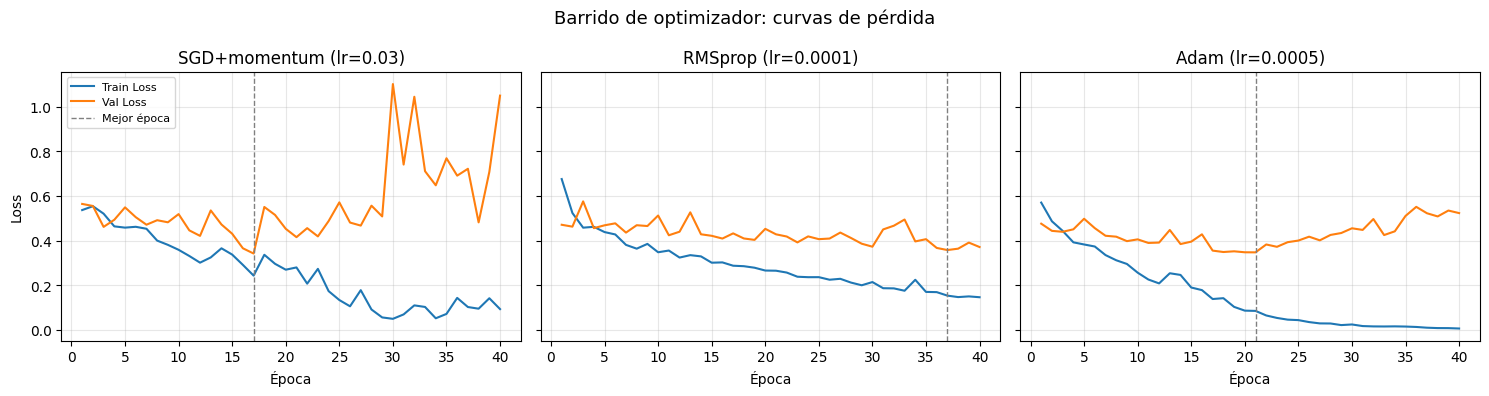

In [25]:
# --- Indicadores de convergencia por optimizador (misma función del barrido de lr) ---
opt_df = pd.DataFrame({f"{k} (lr={OPT_CANDIDATES[k]['lr']})": {**convergence_stats(r["history"]),
                                                               "Test Acc": round(r["test_acc"], 4)}
                       for k, r in opt_sweep.items()}).T
display(opt_df)

# --- Curvas de Train/Val Loss por optimizador ---
fig, axes = plt.subplots(1, len(OPT_CANDIDATES), figsize=(5 * len(OPT_CANDIDATES), 4), sharey=True)
for ax, (name, r) in zip(axes, opt_sweep.items()):
    h = r["history"]
    ep = range(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], label="Train Loss")
    ax.plot(ep, h["val_loss"], label="Val Loss")
    ax.axvline(h["best_epoch"] + 1, ls="--", color="gray", lw=1, label="Mejor época")
    ax.set_title(f"{name} (lr={OPT_CANDIDATES[name]['lr']})")
    ax.set_xlabel("Época")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)
plt.suptitle("Barrido de optimizador: curvas de pérdida", fontsize=13)
plt.tight_layout()
plt.show()


En este caso nos podemos dar cuenta que en los optimizadores con tasas muy bajas, el modelo converge lento y no alcanza un buen mínimo en 40 épocas. Con tasas muy altas, el entrenamiento se vuelve inestable. En los tres casos el mejor valor quedó dentro del rango evaluado, lo que confirma que se encontró el óptimo de cada uno. Así, en SGD + momentum el Val Loss mejora de 0.4501 con lr = 1e-3 a 0.3419 con lr = 3e-2, pero vuelve a empeorar a 0.4753 con lr = 1e-1. Cada optimizador funciona mejor en un rango distinto, separados aproximadamente por un orden de magnitud, RMSprop alrededor de 1e-4, Adam entre 5e-4 y 1e-3, y SGD + momentum alrededor de 3e-2. Esto confirma que comparar los optimizadores con un mismo lr habría favorecido artificialmente a alguno de ellos.

Con su mejor lr, los tres optimizadores alcanzaron un Val Loss muy similar, en donde SGD + momentum obtuvo 0.3419, Adam 0.3472 y RMSprop 0.3575. La diferencia entre SGD y Adam es de solo 0.005, que no es significativa con 64 imágenes de validación. Sin embargo, su dinámica de entrenamiento fue muy distinta. SGD + momentum presentó la curva de validación más inestable, con una oscilación de 0.165 frente a 0.032 de Adam y picos que superan 1.0 después de la época 17. RMSprop fue el más lento en converger, con su mejor época en la 37. Adam alcanzó su mínimo en la época 21 con la curva más estable de los tres, y además mostró el rango de lr más amplio con buenos resultados (0.3472 y 0.3487 con 5e-4 y 1e-3).

La hipótesis se cumple solo parcialmente. RMSprop sí convergió más lento, pero SGD + momentum no presentó una trayectoria más suave, sino más inestable, ya que necesitó una tasa de aprendizaje alta para alcanzar un buen desempeño. En conclusión, aunque SGD + momentum obtuvo el menor Val Loss, la diferencia es despreciable, y Adam ofrece el mejor equilibrio entre desempeño, estabilidad y robustez frente a la elección del lr. Esto justifica su uso como optimizador del modelo base.

## Barrido 7: Diseño factorial — todas las combinaciones de optimizador y técnicas de regularización

En los barridos 1 a 6 se cambia **un factor a la vez**, mientras que la configuración **Combinado** reúne los mejores valores encontrados individualmente. El problema es que este procedimiento asume que las técnicas funcionan de manera independiente, pero esto no necesariamente es así. De hecho, el resultado del Combinado no fue mejor que todas las configuraciones individuales en validación. Por eso, en este experimento se busca analizar si existen **interacciones entre las diferentes técnicas**.

Para esto se plantea un diseño factorial completo, donde se prueban todas las combinaciones posibles entre los optimizadores y las técnicas de regularización.

| Factor            | Nivel "off"            | Nivel "on"                                                                 |
| ----------------- | ---------------------- | -------------------------------------------------------------------------- |
| Optimizador       | —                      | SGD + momentum (`lr=3e-2`), RMSprop (`lr=1e-4`), Adam (`lr=1e-3`)          |
| L2                | `λ = 0`                | `λ = 1e-3` (mejor `λ > 0` del Barrido 1)                                   |
| Dropout           | `p = 0`                | `p = 0.3` (mejor `p > 0` del Barrido 2)                                    |
| Data Augmentation | Sin augmentation       | Leve (mejor nivel del Barrido 3)                                           |
| Early Stopping    | Sin detención temprana | `patience = 5` (mejor valor del Barrido 4)                                 |

Esto da **3 optimizadores × 2⁴ combinaciones de regularización = 48 configuraciones**.

SGD + momentum y RMSprop se utilizan con **su mejor tasa de aprendizaje** encontrada en el Barrido 6, para que la comparación entre optimizadores sea justa. Para Adam se mantiene `lr = 1e-3`, el del baseline, ya que la diferencia con 5e-4 fue despreciable (0.3472 frente a 0.3487); así los resultados de Adam en el factorial son directamente comparables con los barridos 1 a 4 y con la configuración Combinado.

Para L2 y Dropout se utiliza como nivel "on" el mejor valor **distinto de cero** encontrado en cada barrido. Esto se hace porque en ambos casos el mejor resultado global fue 0, pero usar 0 como nivel "on" sería equivalente a no aplicar la técnica y no permitiría evaluar su efecto.

No se utiliza una grilla con todos los valores posibles de cada barrido porque el número de entrenamientos sería demasiado grande. Al combinar todos los valores (5 valores de λ × 5 de p × 4 niveles de augmentation × 3 valores de patience × 13 combinaciones de optimizador y learning rate) se tendrían **3.900 entrenamientos**, lo que no sería práctico. Con el diseño factorial se pueden estudiar las interacciones entre las técnicas con solo **48 configuraciones**.

**Variables controladas:** arquitectura, semilla 42, partición de los datos, batch size de 32 y un máximo de 40 épocas. Cuando Early Stopping está activo, el entrenamiento puede terminar antes de llegar a las 40 épocas.

**Hipótesis:** si las técnicas interactúan entre sí, la mejor combinación del diseño factorial puede ser diferente de la configuración **Combinado**. Además, el efecto de una técnica puede cambiar dependiendo del optimizador y de las demás técnicas que estén activas.

**Criterio de selección:** al igual que en los barridos anteriores, se selecciona la configuración con el menor **Val Loss**. El conjunto de test no se utiliza para elegir la configuración, sino únicamente para evaluar el modelo ganador al final.

In [26]:
import itertools

# --- lr usados en el diseño factorial ---
# SGD y RMSprop: mejor lr de su barrido (Barrido 6).
# Adam: se mantiene el lr del baseline (1e-3), ya que la diferencia con 5e-4 fue
# despreciable (0.0015) y así el factorial es comparable con los barridos 1-4 y el Combinado.
OPT_CANDIDATES = {
    "SGD+momentum": {"optimizer_name": "sgd",     "lr": 3e-2},
    "RMSprop":      {"optimizer_name": "rmsprop", "lr": 1e-4},
    "Adam":         {"optimizer_name": "adam",    "lr": 1e-3},
}
print("lr del factorial:", {k: v["lr"] for k, v in OPT_CANDIDATES.items()})

# --- Nivel "on" de cada técnica: mejor valor distinto de cero de su barrido individual ---
def best_nonzero(sweep, off_value):
    return min((k for k in sweep if k != off_value),
               key=lambda k: min(sweep[k]["history"]["val_loss"]))

L2_ON   = best_nonzero(l2_sweep, 0.0)
DROP_ON = best_nonzero(dropout_sweep, 0.0)
AUG_ON  = best_nonzero(aug_sweep, "Sin augmentation")
PAT_ON  = best_patience

print(f"Niveles 'on': L2 lambda={L2_ON} | Dropout p={DROP_ON} | "
      f"Augmentation={AUG_ON} | Early Stopping patience={PAT_ON}")

FACTORES = ["L2", "Dropout", "Augmentation", "EarlyStopping"]

def combo_label(flags):
    activos = [f for f, on in zip(FACTORES, flags) if on]
    return " + ".join(activos) if activos else "Sin regularización"

fact_rows = []
fact_histories = {}
best_fact = None          # solo se guarda el MODELO ganador (para no llenar la memoria)

t0 = time.perf_counter()
total = len(OPT_CANDIDATES) * 2 ** len(FACTORES)
k = 0
for opt_name, cfg in OPT_CANDIDATES.items():
    for flags in itertools.product([0, 1], repeat=len(FACTORES)):
        k += 1
        l2_on, drop_on, aug_on, es_on = flags
        model, history, tm = run_single_config(
            weight_decay=L2_ON if l2_on else 0.0,
            dropout_p=DROP_ON if drop_on else 0.0,
            transform_train=AUG_CANDIDATES[AUG_ON] if aug_on else base_resize,
            patience=PAT_ON if es_on else None,
            epochs=SWEEP_EPOCHS,
            lr=cfg["lr"],
            optimizer_name=cfg["optimizer_name"],
        )
        label = combo_label(flags)
        best_val = min(history["val_loss"])
        fact_histories[(opt_name, label)] = history
        fact_rows.append({
            "Optimizador": opt_name, "Combinación": label,
            "L2": l2_on, "Dropout": drop_on, "Augmentation": aug_on, "EarlyStopping": es_on,
            "Épocas": len(history["train_loss"]),
            **convergence_stats(history),
            "Test Loss": round(tm["test_loss"], 4), "Test Acc": round(tm["test_acc"], 4),
        })
        if best_fact is None or best_val < best_fact["best_val"]:
            best_fact = {"model": model, "history": history, **tm,
                         "best_val": best_val, "optimizador": opt_name, "combinacion": label}
        else:
            del model
        print(f"[{k:2d}/{total}] {opt_name:<13} | {label:<45} | best_val_loss={best_val:.4f}")
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

fact_df = pd.DataFrame(fact_rows)
fact_df.to_csv("factorial_results.csv", index=False)   # respaldo para el anexo
print(f"\n[Diseño factorial] {total} configuraciones | Wall time: {time.perf_counter() - t0:.1f}s")
print(f"Mejor combinación según val_loss: {best_fact['optimizador']} | {best_fact['combinacion']} "
      f"(val_loss={best_fact['best_val']:.4f})")

lr del factorial: {'SGD+momentum': 0.03, 'RMSprop': 0.0001, 'Adam': 0.001}
Niveles 'on': L2 lambda=0.001 | Dropout p=0.3 | Augmentation=Leve | Early Stopping patience=5
[ 1/48] SGD+momentum  | Sin regularización                            | best_val_loss=0.3419
[ 2/48] SGD+momentum  | EarlyStopping                                 | best_val_loss=0.4613
[ 3/48] SGD+momentum  | Augmentation                                  | best_val_loss=0.3052
[ 4/48] SGD+momentum  | Augmentation + EarlyStopping                  | best_val_loss=0.3052
[ 5/48] SGD+momentum  | Dropout                                       | best_val_loss=0.3531
[ 6/48] SGD+momentum  | Dropout + EarlyStopping                       | best_val_loss=0.3531
[ 7/48] SGD+momentum  | Dropout + Augmentation                        | best_val_loss=0.2934
[ 8/48] SGD+momentum  | Dropout + Augmentation + EarlyStopping        | best_val_loss=0.3387
[ 9/48] SGD+momentum  | L2                                            | best_val_loss=0

,Optimizador,Combinación,Épocas,Mejor Val Loss,Época mejor Val Loss,Oscilación Val Loss,Gap en mejor época (val-train),Test Acc
0,Adam,Augmentation,40,0.2907,30,0.0647,0.1725,0.7381
1,Adam,L2 + Dropout + Augmentation,40,0.2932,40,0.0458,0.0645,0.7738
2,SGD+momentum,Dropout + Augmentation,40,0.2934,37,0.0560,0.0012,0.7262
3,SGD+momentum,Augmentation + EarlyStopping,22,0.3052,17,0.0573,-0.0088,0.7738
4,SGD+momentum,Augmentation,40,0.3052,17,0.1028,-0.0088,0.7738
5,SGD+momentum,L2 + Augmentation,40,0.3052,37,0.0780,0.1080,0.7619
6,SGD+momentum,L2 + Augmentation + EarlyStopping,25,0.3199,20,0.0511,0.0262,0.7976
7,Adam,L2 + Augmentation,40,0.3222,30,0.0457,0.1439,0.7262
8,Adam,L2 + Dropout + Augmentation + EarlyStopping,25,0.3222,20,0.0169,0.0035,0.8810
9,Adam,Augmentation + EarlyStopping,23,0.3270,18,0.0495,0.0601,0.8571


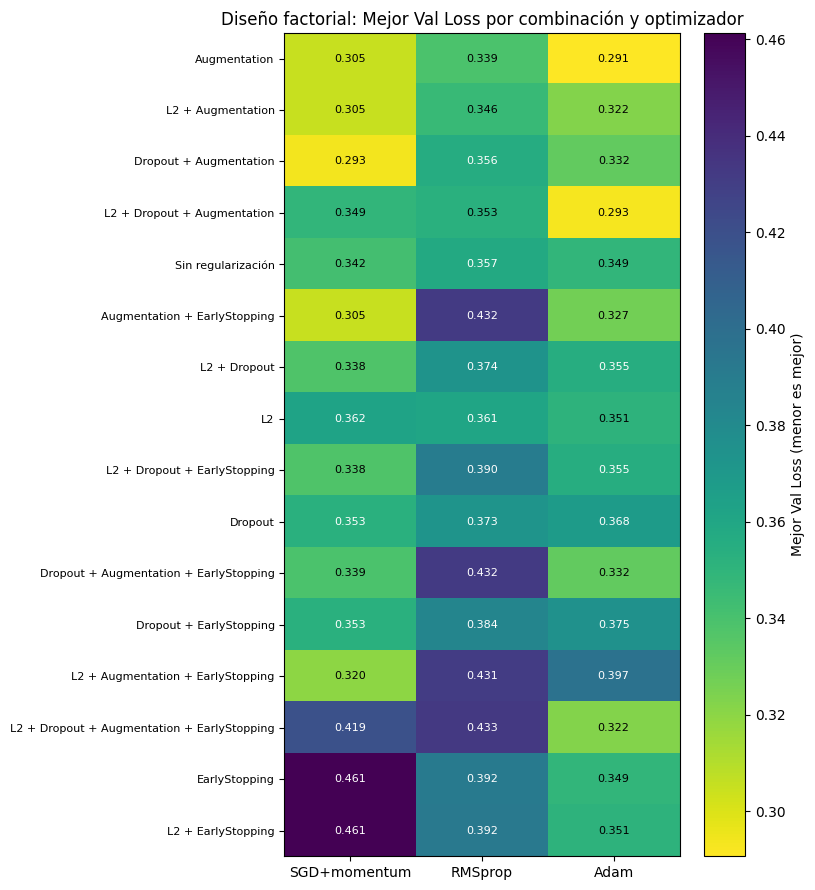

In [27]:
# --- Top 10 configuraciones según Val Loss (la tabla completa va al anexo) ---
cols = ["Optimizador", "Combinación", "Épocas", "Mejor Val Loss", "Época mejor Val Loss",
        "Oscilación Val Loss", "Gap en mejor época (val-train)", "Test Acc"]
display(fact_df.sort_values("Mejor Val Loss")[cols].head(10).reset_index(drop=True))

# --- Mapa de calor: Mejor Val Loss por combinación x optimizador ---
pivot = fact_df.pivot(index="Combinación", columns="Optimizador", values="Mejor Val Loss")
pivot = pivot.loc[pivot.mean(axis=1).sort_values().index, list(OPT_CANDIDATES)]

fig, ax = plt.subplots(figsize=(8, 9))
# vmax acotado para que una corrida que diverja no aplaste la escala de color
vmax = min(np.nanmax(pivot.values), 1.0)
im = ax.imshow(pivot.values, cmap="viridis_r", aspect="auto", vmax=vmax)
ax.set_xticks(range(pivot.shape[1])); ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(pivot.shape[0])); ax.set_yticklabels(pivot.index, fontsize=8)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8,
                color="white" if v > np.nanmedian(pivot.values) else "black")  # v>1 = divergió
fig.colorbar(im, ax=ax, label="Mejor Val Loss (menor es mejor)")
ax.set_title("Diseño factorial: Mejor Val Loss por combinación y optimizador")
plt.tight_layout()
plt.show()


,SGD+momentum,RMSprop,Adam
L2,0.0176,0.0018,0.0032
Dropout,-0.0100,0.0053,-0.0006
Augmentation,-0.0466,0.0125,-0.0295
EarlyStopping,0.0435,0.0533,0.0184


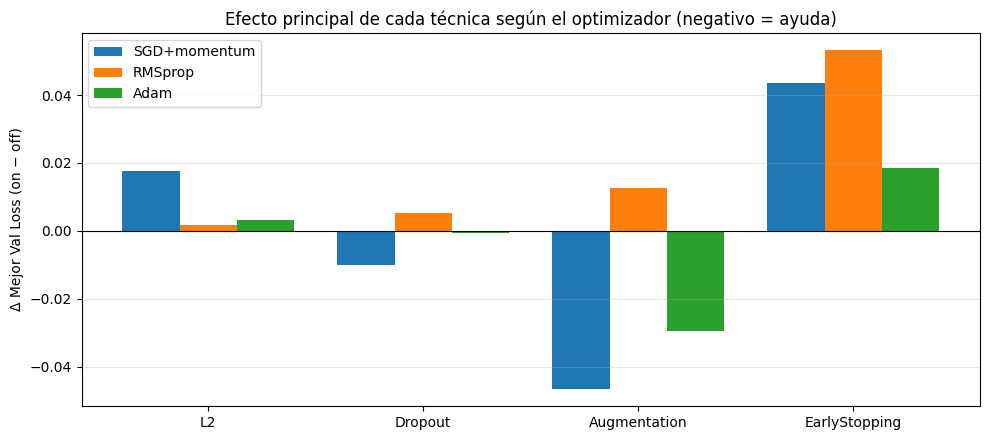

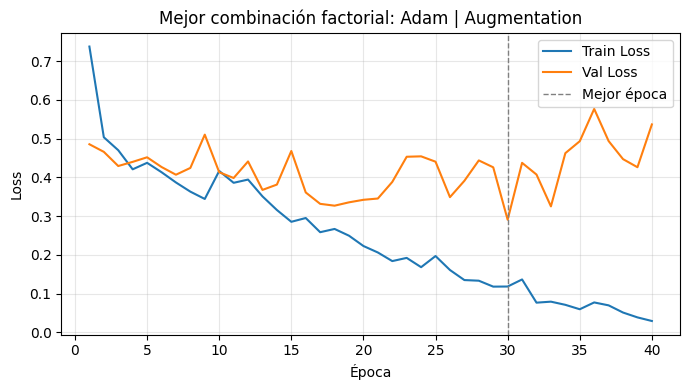

In [28]:
# --- Efectos principales: cuánto cambia el Val Loss al ACTIVAR cada técnica ---
# Para cada optimizador y cada técnica se promedia el Mejor Val Loss de las 8
# combinaciones con la técnica activada y de las 8 con la técnica desactivada.
# Efecto = promedio(on) - promedio(off). Negativo = la técnica ayuda.
efectos = {}
for opt_name in OPT_CANDIDATES:
    sub = fact_df[fact_df["Optimizador"] == opt_name]
    efectos[opt_name] = {f: sub[sub[f] == 1]["Mejor Val Loss"].mean()
                            - sub[sub[f] == 0]["Mejor Val Loss"].mean()
                         for f in FACTORES}
efectos_df = pd.DataFrame(efectos).round(4)
display(efectos_df)

x = np.arange(len(FACTORES))
w = 0.8 / len(OPT_CANDIDATES)
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, opt_name in enumerate(OPT_CANDIDATES):
    ax.bar(x + i * w - 0.4 + w / 2, efectos_df[opt_name], width=w, label=opt_name)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(FACTORES)
ax.set_ylabel("Δ Mejor Val Loss (on − off)")
ax.set_title("Efecto principal de cada técnica según el optimizador (negativo = ayuda)")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# --- Curvas de la mejor combinación factorial ---
h = best_fact["history"]
ep = range(1, len(h["train_loss"]) + 1)
plt.figure(figsize=(7, 4))
plt.plot(ep, h["train_loss"], label="Train Loss")
plt.plot(ep, h["val_loss"], label="Val Loss")
plt.axvline(h["best_epoch"] + 1, ls="--", color="gray", lw=1, label="Mejor época")
plt.title(f"Mejor combinación factorial: {best_fact['optimizador']} | {best_fact['combinacion']}")
plt.xlabel("Época"); plt.ylabel("Loss"); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


### Análisis del diseño factorial

**Mejor combinación.** La configuración con menor Val Loss fue **Adam + Augmentation**, con un valor de 0.2907. Esta fue también la combinación que había obtenido el mejor resultado en el barrido individual de Data Augmentation. Sin embargo, las primeras posiciones están muy cerca entre sí: **Adam + L2 + Dropout + Augmentation** obtuvo 0.2932 y **SGD + momentum + Dropout + Augmentation** obtuvo 0.2934. La diferencia entre estas configuraciones es menor a 0.003, por lo que con solo 64 imágenes de validación no se puede considerar una diferencia relevante.

Lo que sí se observa claramente es que **las 10 mejores configuraciones incluyen Data Augmentation**. Además, la configuración **Combinado** (Adam + Augmentation + Early Stopping), con un Val Loss de 0.3270, quedó en el puesto 10 de 48. Esto muestra que simplemente juntar los mejores valores de los barridos individuales no garantiza obtener la mejor combinación.

**Efectos principales.**

| Técnica        | SGD + momentum |    RMSprop |       Adam |
| -------------- | -------------: | ---------: | ---------: |
| L2             |         +0.018 |     +0.002 |     +0.003 |
| Dropout        |         −0.010 |     +0.005 |     −0.001 |
| Augmentation   |     **−0.047** |     +0.013 | **−0.030** |
| Early Stopping |     **+0.044** | **+0.053** | **+0.018** |

*Cambio promedio en el mejor Val Loss al activar cada técnica. Un valor negativo significa que el Val Loss disminuye y, por tanto, hay una mejora.*

* **Data Augmentation** es la técnica que más mejora el Val Loss con SGD + momentum y Adam. En RMSprop el efecto promedio aparece como positivo, pero esto no significa que Augmentation no funcione. Por sí sola sí mejora el resultado, pasando de 0.357 a 0.339. El promedio aumenta principalmente por su combinación con Early Stopping.

* **Early Stopping** empeora el Val Loss con los tres optimizadores. Con `patience = 5`, en varias configuraciones el entrenamiento se detiene antes de llegar al mínimo. Esto ocurre especialmente porque algunas curvas alcanzan su mejor resultado en épocas más avanzadas; por ejemplo, la mejor combinación llega a su mínimo en la época 30.

* **L2 y Dropout** tienen efectos pequeños con Adam y RMSprop, lo que coincide con los resultados de los barridos individuales. En SGD + momentum, Dropout sí presenta una pequeña mejora (−0.010), mientras que L2 empeora el resultado (+0.018). Esto muestra que el efecto de estas técnicas también depende del optimizador utilizado.

**Interacciones encontradas.**

1. **Augmentation × Early Stopping.** Augmentation mejora el resultado cuando se utiliza sola, pero al combinarla con Early Stopping pierde parte de ese beneficio. Por ejemplo, con RMSprop, Augmentation sola obtiene 0.339, mientras que al agregar Early Stopping el Val Loss sube a 0.432. Con Adam pasa de 0.291 a 0.327. Esto puede explicarse porque Augmentation hace que la curva de validación tenga más variaciones y que el mejor resultado aparezca más tarde. Como consecuencia, Early Stopping puede detener el entrenamiento antes de llegar a ese mínimo.

2. **Optimizador × Early Stopping.** El efecto de Early Stopping también depende del optimizador. Con SGD + momentum y Augmentation, el mínimo aparece en la época 17, por lo que Early Stopping no cambia el resultado ya que ambas configuraciones obtienen 0.3052. En Adam y RMSprop, el mínimo aparece más tarde y Early Stopping puede detener el entrenamiento antes de alcanzarlo. Además, como se restauran los pesos de la mejor época, si Early Stopping no interrumpe antes del mínimo, el resultado puede ser exactamente el mismo con o sin esta técnica.

3. **L2 + Dropout + Augmentation en Adam.** Aunque L2 y Dropout por separado tienen poco efecto, al combinarlos con Augmentation se obtiene un resultado muy cercano al mejor con 0.2932 frente a 0.2907. Además, esta combinación presenta una menor diferencia entre Train Loss y Val Loss en su mejor época (0.065 frente a 0.173) y una curva más estable (oscilación de 0.046 frente a 0.065). Esto muestra que algunas técnicas que por separado aportan poco pueden funcionar mejor cuando se combinan con otra técnica.

**En conclusión,** el diseño factorial muestra que las técnicas no funcionan de manera independiente. El efecto de cada una cambia dependiendo del optimizador y de las demás técnicas que estén activas. **Data Augmentation fue la técnica que mostró el efecto más claro y consistente**, mientras que Early Stopping con `patience = 5` empeoró el resultado en la mayoría de las combinaciones, especialmente cuando se combinó con Augmentation. Adam también mostró un comportamiento consistente y obtuvo el mejor resultado en varias de las combinaciones.

**Limitaciones:** se evaluaron 48 configuraciones utilizando solamente 64 imágenes de validación, por lo que pequeñas diferencias entre las primeras posiciones pueden deberse al azar. Por esta razón, configuraciones con resultados prácticamente iguales se consideran equivalentes. El conjunto de test se utiliza únicamente para la evaluación final y no para seleccionar la configuración.

Aunque **Adam + L2 + Dropout + Augmentation + Early Stopping** obtuvo el mayor Test Acc (0.881), no se selecciona como configuración final, ya que en validación quedó en la posición 9. Elegirla basándose en el resultado de test implicaría utilizar el conjunto de test para tomar una decisión, lo cual rompería el procedimiento establecido.


# 5.Comparación Final

Una vez realizados los diferentes barridos de hiperparámetros, se construye la comparación final entre las configuraciones evaluadas. En primer lugar, se utiliza como referencia el baseline, correspondiente al caso lambda=0.0 del barrido de L2, el cual no incorpora regularización L2.

A continuación, se incluyen los mejores resultados obtenidos individualmente en cada uno de los barridos: L2, Dropout, Augmentation y Early Stopping.

Finalmente, se construye la configuración combinada. Esta configuración no corresponde a un nuevo barrido de hiperparámetros, sino a una única ejecución del modelo en la que se utilizan simultáneamente los mejores valores identificados previamente en cada experimento individual.

En particular, la configuración combinada utiliza `best_lambda`, `best_dropout`, `best_aug` y `best_patience`, correspondientes respectivamente a los mejores valores encontrados para L2, Dropout, Augmentation y Early Stopping. Con estos parámetros se vuelve a entrenar el modelo y se obtienen sus métricas sobre el conjunto de prueba.

Por tanto, la comparación permite observar dos aspectos diferentes. Primero, el efecto individual de cada estrategia de regularización o entrenamiento frente al baseline; y segundo, el comportamiento de una configuración que combina los mejores hiperparámetros encontrados de forma independiente.

Además, se incluyen en la tabla la mejor tasa de aprendizaje (Barrido 5), el mejor optimizador (Barrido 6) y la mejor combinación del diseño factorial (Barrido 7). Hay que tener en cuenta que varias filas corresponden al mismo modelo que el baseline (Mejor L2 con λ = 0, Mejor Dropout con p = 0 y Mejor Early Stopping, que restaura la misma mejor época), y que la mejor combinación factorial (Adam + Augmentation) coincide con Mejor Augmentation (Leve).


In [29]:
# La configuración combinada usa los MEJORES valores encontrados en cada barrido individual.
model, history, test_metrics = run_single_config(
    dropout_p=best_dropout,
    weight_decay=best_lambda,
    transform_train=AUG_CANDIDATES[best_aug],
    epochs=ES_EPOCHS,
    patience=best_patience,
)

combinado = {
    "model": model,
    "history": history,
    **test_metrics,
    "epochs_run": len(history["train_loss"]),
    "best_val_loss": min(history["val_loss"]),
    "best_val_acc": max(history["val_acc"]),
    "final_gap": history["train_loss"][-1] - history["val_loss"][-1],
}

results = {
    "Baseline (sin regularización)": l2_sweep[0.0],
    f"Mejor L2 (lambda={best_lambda})": l2_sweep[best_lambda],
    f"Mejor Dropout (p={best_dropout})": dropout_sweep[best_dropout],
    f"Mejor Augmentation ({best_aug})": aug_sweep[best_aug],
    f"Mejor Early Stopping (patience={best_patience})": es_sweep[best_patience],
    f"Mejor Learning Rate (lr={best_lr})": lr_sweep[best_lr],
    f"Mejor Optimizador ({best_opt})": opt_sweep[best_opt],
    f"Mejor factorial ({best_fact['optimizador']} | {best_fact['combinacion']})": best_fact,
    "Combinado (mejores de cada barrido)": combinado,
}

## Resultados comparativos

Primero se analizan las curvas de `val_loss` y `val_acc` dentro de cada barrido (L2, Dropout, Augmentation y Early Stopping). Estas curvas permiten identificar y justificar la selección del mejor valor para cada técnica.

Posteriormente, se realiza la comparación entre las mejores configuraciones obtenidas en cada barrido, incluyendo el baseline y la configuración combinada.

La configuración combinada corresponde a una nueva ejecución del modelo utilizando simultáneamente los mejores valores encontrados para L2, Dropout, Augmentation y Early Stopping.


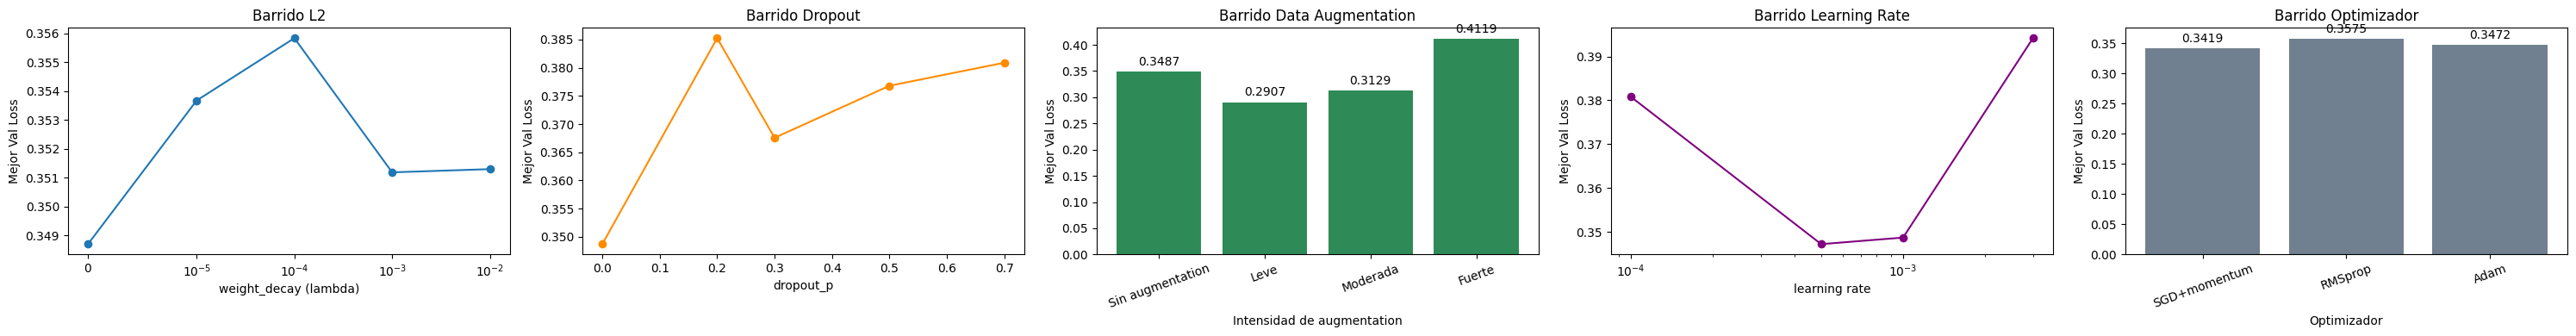

In [30]:
fig, axes = plt.subplots(1, 5, figsize=(30, 4))

l2_x = list(l2_sweep.keys())
l2_y = [min(l2_sweep[k]["history"]["val_loss"]) for k in l2_x]
axes[0].plot(l2_x, l2_y, marker="o")
axes[0].set_xscale("symlog", linthresh=1e-5)
axes[0].set_xlabel("weight_decay (lambda)"); axes[0].set_ylabel("Mejor Val Loss")
axes[0].set_title("Barrido L2")

drop_x = list(dropout_sweep.keys())
drop_y = [min(dropout_sweep[k]["history"]["val_loss"]) for k in drop_x]
axes[1].plot(drop_x, drop_y, marker="o", color="darkorange")
axes[1].set_xlabel("dropout_p"); axes[1].set_ylabel("Mejor Val Loss")
axes[1].set_title("Barrido Dropout")

aug_x = list(aug_sweep.keys())
aug_y = [min(aug_sweep[k]["history"]["val_loss"]) for k in aug_x]
bars = axes[2].bar(aug_x, aug_y, color="seagreen")
axes[2].bar_label(bars, fmt="%.4f", padding=3)
axes[2].set_xlabel("Intensidad de augmentation"); axes[2].set_ylabel("Mejor Val Loss")
axes[2].set_title("Barrido Data Augmentation")
axes[2].tick_params(axis="x", rotation=20)

lr_x = list(lr_sweep.keys())
lr_y = [min(lr_sweep[k]["history"]["val_loss"]) for k in lr_x]
axes[3].plot(lr_x, lr_y, marker="o", color="purple")
axes[3].set_xscale("log")
axes[3].set_xlabel("learning rate"); axes[3].set_ylabel("Mejor Val Loss")
axes[3].set_title("Barrido Learning Rate")

opt_x = list(opt_sweep.keys())
opt_y = [min(opt_sweep[k]["history"]["val_loss"]) for k in opt_x]
bars_opt = axes[4].bar(opt_x, opt_y, color="slategray")
axes[4].bar_label(bars_opt, fmt="%.4f", padding=3)
axes[4].set_xlabel("Optimizador"); axes[4].set_ylabel("Mejor Val Loss")
axes[4].set_title("Barrido Optimizador")
axes[4].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


In [31]:
comparison_df = pd.DataFrame({
    name: {
        "Épocas ejecutadas": len(r["history"]["train_loss"]),
        "Mejor Val Loss": round(min(r["history"]["val_loss"]), 4),
        "Mejor Val Acc": round(max(r["history"]["val_acc"]), 4),
        "Test Loss": round(r["test_loss"], 4),
        "Test Acc": round(r["test_acc"], 4),
        "Gap (val-train) final": round(
            r["history"]["val_loss"][-1] - r["history"]["train_loss"][-1], 4
        ),
    }
    for name, r in results.items()
}).T

comparison_df


,Épocas ejecutadas,Mejor Val Loss,Mejor Val Acc,Test Loss,Test Acc,Gap (val-train) final
Baseline (sin regularización),40.0,0.3487,0.9375,0.5063,0.7976,0.6287
Mejor L2 (lambda=0.0),40.0,0.3487,0.9375,0.5063,0.7976,0.6287
Mejor Dropout (p=0.0),40.0,0.3487,0.9375,0.5063,0.7976,0.6287
Mejor Augmentation (Leve),40.0,0.2907,0.9219,0.7364,0.7381,0.5078
Mejor Early Stopping (patience=5),22.0,0.3487,0.9375,0.5063,0.7976,0.5414
Mejor Learning Rate (lr=0.0005),40.0,0.3472,0.9375,0.4743,0.7738,0.5171
Mejor Optimizador (SGD+momentum),40.0,0.3419,0.8750,0.5720,0.7619,0.9565
Mejor factorial (Adam | Augmentation),40.0,0.2907,0.9219,0.7364,0.7381,0.5078
Combinado (mejores de cada barrido),23.0,0.3270,0.9062,0.4289,0.8571,0.2613


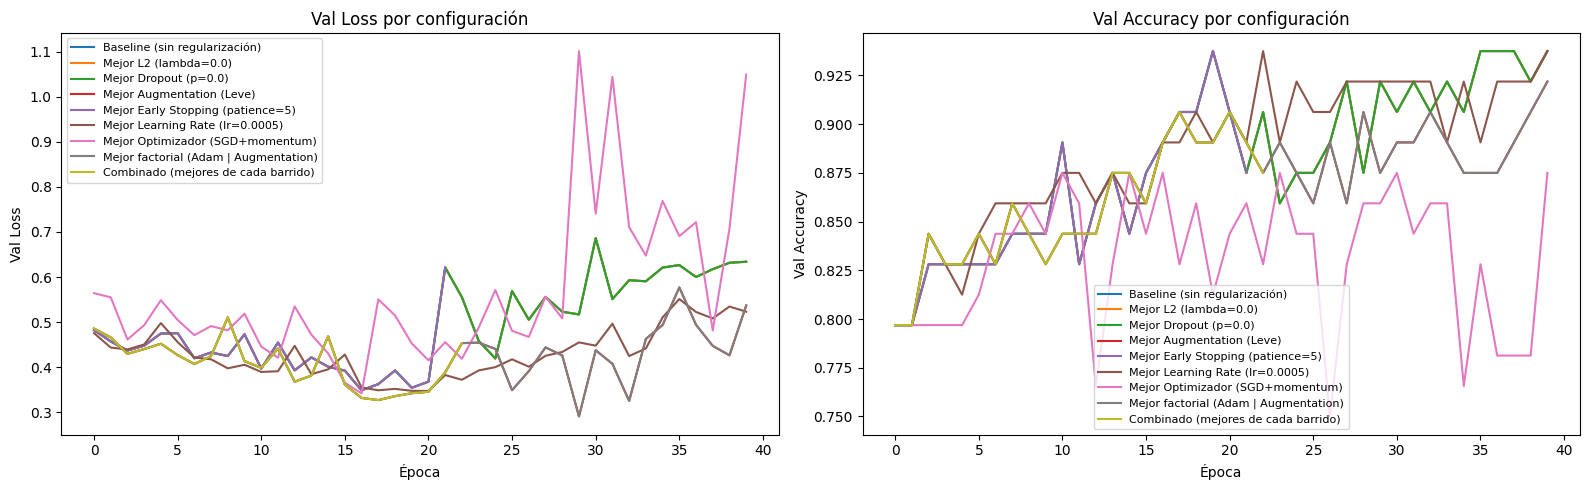

In [32]:
# Curvas comparativas de Val Loss y Val Accuracy entre TODAS las configuraciones
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for name, r in results.items():
    axes[0].plot(r["history"]["val_loss"], label=name)
    axes[1].plot(r["history"]["val_acc"], label=name)

axes[0].set_title("Val Loss por configuración")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Val Loss")
axes[0].legend(fontsize=8)

axes[1].set_title("Val Accuracy por configuración")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Val Accuracy")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


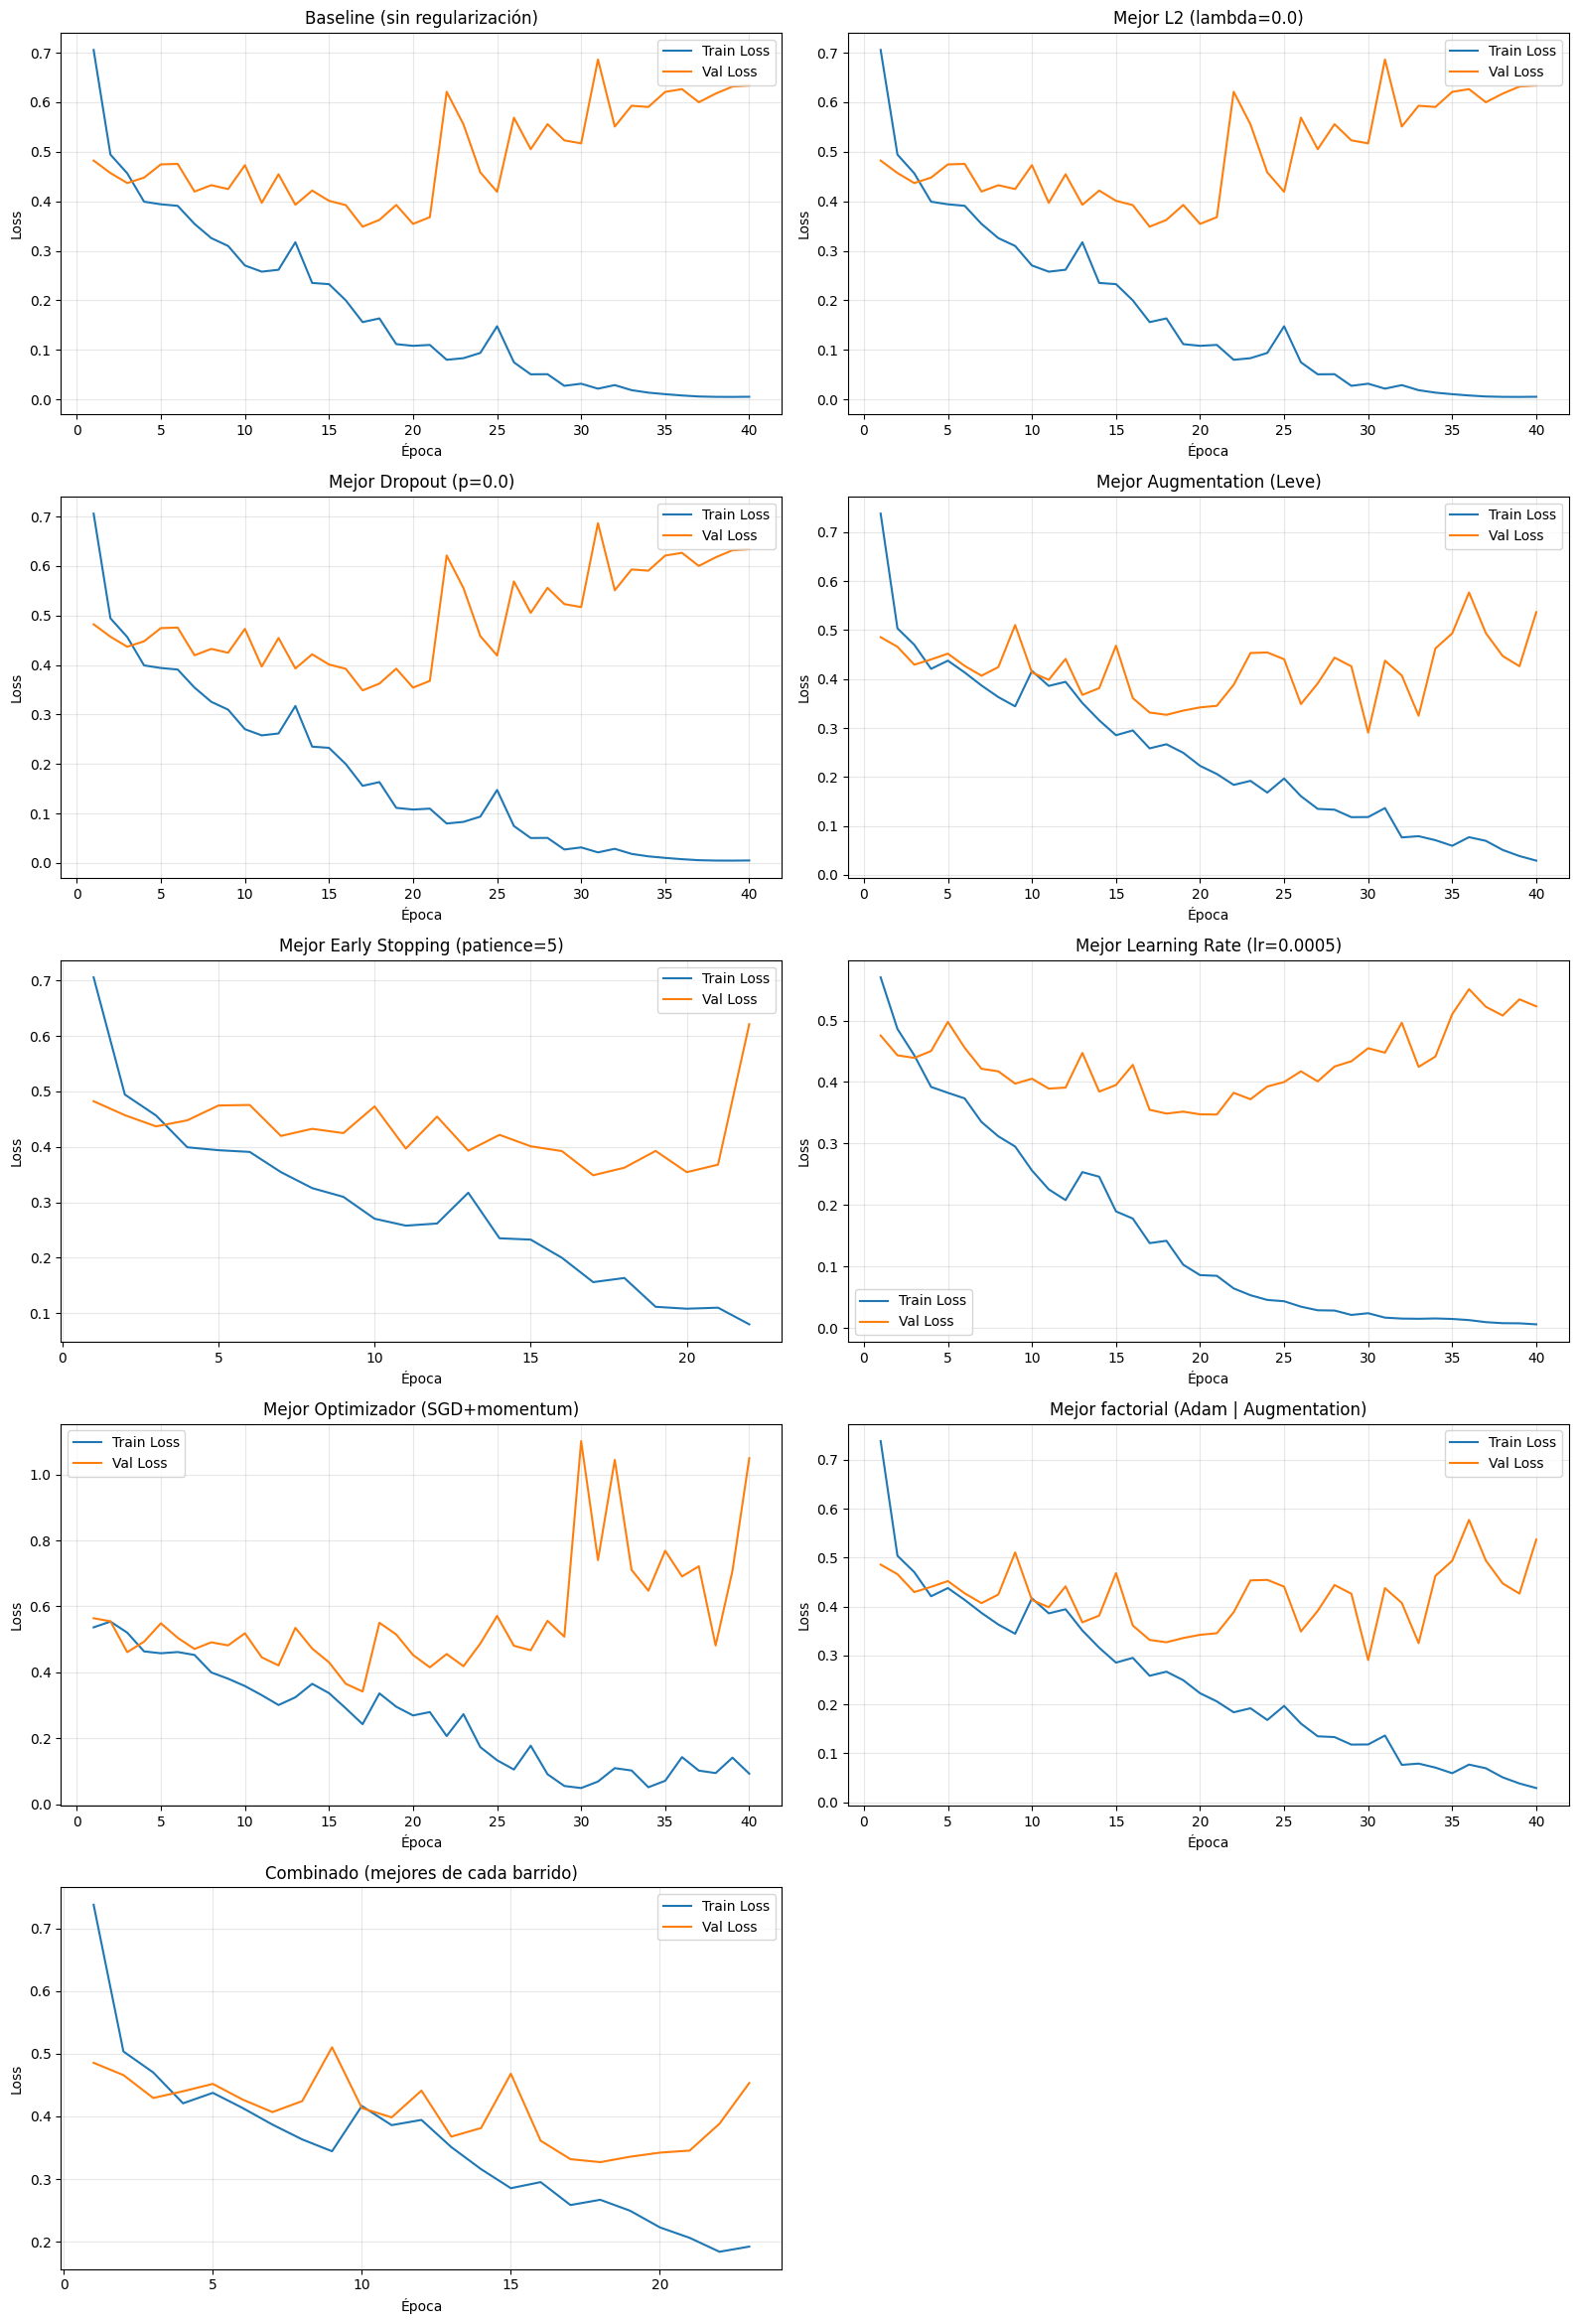

In [33]:
n_rows = int(np.ceil(len(results) / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(16, 4.7 * n_rows))

axes = axes.flatten()

for ax, (name, r) in zip(axes, results.items()):
    history = r["history"]

    epochs = range(1, len(history["train_loss"]) + 1)

    ax.plot(epochs, history["train_loss"], label="Train Loss")
    ax.plot(epochs, history["val_loss"], label="Val Loss")

    ax.set_title(name)
    ax.set_xlabel("Época")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

for ax in axes[len(results):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 6.Métricas

In [34]:
def compute_full_metrics(model, loader, threshold=0.5):
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            probs = model(xb).cpu().numpy().ravel()
            all_probs.extend(probs)
            all_labels.extend(yb.numpy().ravel())

    y_true = np.array(all_labels).astype(int)
    y_prob = np.array(all_probs)
    y_pred = (y_prob >= threshold).astype(int)

    return {
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall":    recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1":        f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "roc_auc":   roc_auc_score(y_true, y_prob),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=[0, 1]),
        "y_true": y_true, "y_pred": y_pred, "y_prob": y_prob,
    }

_, _, test_loader_eval = make_loaders()

full_metrics = {name: compute_full_metrics(r["model"], test_loader_eval)
                for name, r in results.items()}

metrics_df = pd.DataFrame({
    name: {
        "Accuracy": round(m["accuracy"], 4),
        "Precision (Glaucoma)": round(m["precision"], 4),
        "Recall (Glaucoma)": round(m["recall"], 4),
        "F1 (Glaucoma)": round(m["f1"], 4),
        "ROC-AUC": round(m["roc_auc"], 4),
    }
    for name, m in full_metrics.items()
}).T

metrics_df

,Accuracy,Precision (Glaucoma),Recall (Glaucoma),F1 (Glaucoma),ROC-AUC
Baseline (sin regularización),0.7976,0.5000,0.5294,0.5143,0.7770
Mejor L2 (lambda=0.0),0.7976,0.5000,0.5294,0.5143,0.7770
Mejor Dropout (p=0.0),0.7976,0.5000,0.5294,0.5143,0.7770
Mejor Augmentation (Leve),0.7381,0.3529,0.3529,0.3529,0.7068
Mejor Early Stopping (patience=5),0.7976,0.5000,0.5294,0.5143,0.7770
Mejor Learning Rate (lr=0.0005),0.7738,0.4500,0.5294,0.4865,0.8411
Mejor Optimizador (SGD+momentum),0.7619,0.4286,0.5294,0.4737,0.7559
Mejor factorial (Adam | Augmentation),0.7381,0.3529,0.3529,0.3529,0.7068
Combinado (mejores de cada barrido),0.8571,0.6667,0.5882,0.6250,0.8165


Dado que el dataset presenta un desbalance de clases es decir 79% Sano y 21% Glaucoma, la Accuracy por sí sola no es suficiente para evaluar el modelo ya que un clasificador que prediga siempre Sano ya estaría obteniendo un accuracy relativamente alta sin utilidad clínica real. Por eso el análisis se centra en Precision, Recall, F1 y ROC-AUC de la clase Glaucoma.

El Baseline obtiene Precision=0.5000, Recall=0.5294, F1=0.5143 y ROC-AUC=0.7770, mientras que Combinado mejora en las cuatro métricas, con Precision=0.6667, Recall=0.5882, F1=0.6250 y ROC-AUC=0.8165. En este caso que es más hacía aspectos clínicos, el Recall es la métrica más relevante, ya que un falso negativo es decir glaucoma no detectado, es más costoso que un falso positivo; Combinado detecta una proporción algo mayor de los casos reales de glaucoma que el baseline, aunque el margen de mejora sigue siendo limitado.

Llama la atención que Augmentation Leve, a pesar de tener el mejor Val Loss del barrido con 0.2907, obtiene las métricas de clasificación más bajas de toda la tabla con Recall=0.3529 y ROC-AUC=0.7068. Esto muestra que el criterio usado para seleccionar hiperparámetros Val Loss no garantiza el mejor resultado en todas las métricas de generalización.

Por otro lado, la configuración con `lr = 5e-4` obtuvo el mayor ROC-AUC de la tabla (0.8411), aunque su Accuracy y su F1 fueron menores que los del baseline. Esto refuerza que, con solo 84 imágenes de prueba, las diferencias entre configuraciones en test son pequeñas y poco estables, y que ninguna métrica por sí sola permite declarar un ganador claro.


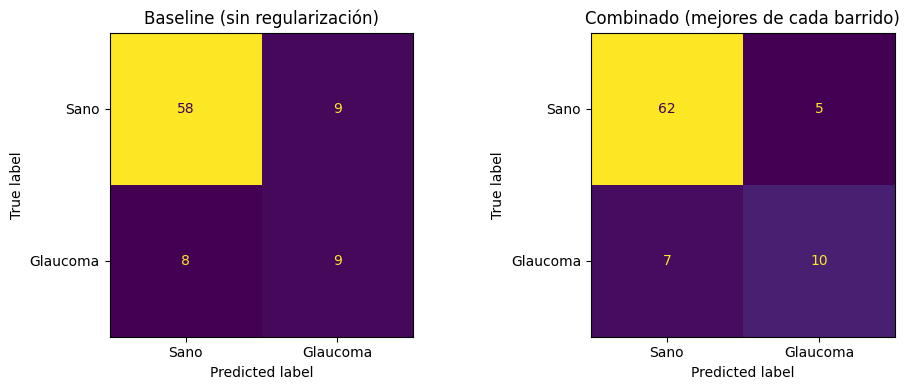

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["Baseline (sin regularización)",
                           "Combinado (mejores de cada barrido)"]):
    cm = full_metrics[name]["confusion_matrix"]
    disp = ConfusionMatrixDisplay(cm, display_labels=["Sano", "Glaucoma"])
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()


En la matriz de confusión nos pudimos dar cuenta de que, en el conjunto de prueba con 84 imágenes, aproximadamente 17 corresponden a glaucoma y 67 a pacientes sanos. El Baseline clasifica correctamente 9 de los 17 casos de glaucoma, dejando 8 falsos negativos, mientras que Combinado identifica correctamente 10 de los 17 casos, reduciendo los falsos negativos a 7. Además, Combinado también reduce los falsos positivos, pasando de 9 en Baseline a 5.

Es decir, Combinado no solo mejora la accuracy global, sino que también logra identificar correctamente un caso adicional de glaucoma y reduce los errores tanto en falsos negativos como en falsos positivos. Esto es importante porque, en este problema, los falsos negativos representan casos reales de glaucoma que el modelo clasifica como sanos, por lo que son un tipo de error especialmente relevante desde el punto de vista clínico.